# Travel Reimbursement Approval Agent

An agentic prototype that reviews employee travel reimbursement claims against the policy in
Appendix A and returns a structured decision: `APPROVE`, `PARTIAL_APPROVE`, `REJECT` or
`MANUAL_REVIEW`.

---

## README

### What this is

A single notebook that runs top-to-bottom with no manual steps. It evaluates the five
Appendix B claims and prints a JSON array of results in the final cell.

### The one idea worth knowing

**The LLM reasons; Python counts.** A deterministic engine owns every number and every
mechanical policy trigger. The language model drives the investigation, reads what no field
encodes, and may only ever make the outcome *more* cautious: it cannot approve money, raise
an amount, or reverse an escalation. That asymmetry is enforced in code (`decide`), proved by
the ablation cell, and tested in the tests cell.

### Setup

```bash
python3 -m venv .venv && source .venv/bin/activate
pip install pydantic pandas matplotlib ipywidgets notebook
jupyter notebook abhijeettiwari.ipynb      # then Run All
```

The first code cell installs anything missing, so `pip install` is optional.

### Environment variables (all optional)

| Variable | Default | Effect |
|---|---|---|
| `USE_LLM` | `1` | `0` runs the deterministic engine alone. The notebook still completes and still emits valid output. |
| `REFRESH_LLM_CACHE` | `0` | `1` ignores `llm_cache.json` and calls the model fresh. |
| `OPENCODE_MODEL` | `opencode/nemotron-3-ultra-free` | Which OpenCode Zen model to drive. |
| `ANTHROPIC_API_KEY` | unset | If set, the Anthropic transport is used instead of opencode. |
| `LLM_TIMEOUT_S` | `180` | Per-call transport timeout. |

### How to run the demo

Run all cells. With a warm `llm_cache.json` the whole notebook completes in seconds; a cold
run calls the model and takes a few minutes. **No credentials are required**: with no LLM
reachable the notebook falls back to the deterministic engine and every assertion still
passes.

### Which LLM, and why this shape

The default is **`opencode/nemotron-3-ultra-free`** via the `opencode` CLI: free, local to
the user's existing login, no API key. One constraint shaped the whole design: OpenCode Zen's
HTTP endpoint **rejects free-tier models from outside opencode**
(`403 FreeTierError`), so there is no OpenAI-style function-calling API available. Tool use is
therefore a **JSON protocol over a subprocess**: the model emits
`{"thought": ..., "action": ..., "args": {...}}`, the host executes the tool and feeds the
observation back. One `AnthropicTransport` is included for anyone with a key; it routes
through the *same* loop, so there is only ever one orchestration code path.

### Deliverable map

| Cell / file | What it covers |
|---|---|
| This cell | README: setup, env vars, how to run, key design choices |
| *Architecture* | the decision-authority split and trigger precedence |
| `policy_lookup` | context grounding over the 13 `POL-*` rules |
| `check_line_items`, `check_claim_level`, `validate_output` | the deterministic tools |
| `Agent.investigate` | the agentic loop, the LLM choosing tools |
| `decide` | monotonic-tightening merge |
| *Audit trail* | retrieved context, tools called, intermediate checks |
| *Ablation* | evidence that the LLM changes outcomes |
| `## Dashboard` | data-driven results dashboard |
| *UI* | interactive panel; screenshots in `UI SS_1.png` / `UI SS_2.png` |
| *Tests* | the five expected outcomes plus the paths Appendix B leaves unexercised |
| *Design Notes & Reasoning* | assumptions, trade-offs, what's next |
| **Final cell** | the JSON array, nine fields per claim |

In [1]:
# --- Dependency bootstrap -------------------------------------------------------------
# Installs only what is missing, so a re-run on a warm environment is a no-op.
import importlib, subprocess, sys

REQUIRED = {"pydantic": "pydantic>=2", "pandas": "pandas", "matplotlib": "matplotlib"}
OPTIONAL = {"ipywidgets": "ipywidgets"}   # UI only; the notebook runs without it.

missing = []
for mod, spec in REQUIRED.items():
    try:
        importlib.import_module(mod)
    except ImportError:
        missing.append(spec)
if missing:
    print("installing:", ", ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

for mod, spec in OPTIONAL.items():
    try:
        importlib.import_module(mod)
    except ImportError:
        print("optional dependency %s is absent; the interactive UI cell will fall back "
              "to a static render." % mod)

import pandas, matplotlib, pydantic
print("python      ", sys.version.split()[0])
print("pydantic    ", pydantic.VERSION)
print("pandas      ", pandas.__version__)
print("matplotlib  ", matplotlib.__version__)

python       3.14.4
pydantic     2.13.5
pandas       3.0.6
matplotlib   3.11.2


In [2]:
# --- Imports --------------------------------------------------------------------------
from __future__ import annotations

import hashlib
import json
import os
import re
import subprocess
from datetime import date
from decimal import Decimal, ROUND_HALF_UP
from io import StringIO
from shutil import which
from typing import Any, Dict, List, Optional, Tuple

import pandas as pd

ANSI_RE = re.compile(r"\x1b\[[0-9;]*[A-Za-z]")

In [3]:
# --- Configuration --------------------------------------------------------------------
import os

# Set USE_LLM=0 to run the deterministic engine alone. The notebook still completes and
# still emits valid output -- that is the point of the fallback, not an afterthought.
USE_LLM = os.environ.get("USE_LLM", "1") not in ("0", "false", "False")

# The opencode CLI exposes no temperature or seed, so responses are cached by prompt hash.
# Delete llm_cache.json or set REFRESH_LLM_CACHE=1 to force fresh model calls.
REFRESH_LLM_CACHE = os.environ.get("REFRESH_LLM_CACHE", "0") in ("1", "true", "True")
LLM_CACHE_PATH = "llm_cache.json"

OPENCODE_MODEL = os.environ.get("OPENCODE_MODEL", "opencode/nemotron-3-ultra-free")
OPENCODE_AGENT = "policy-reasoner"     # tool-less agent defined in .opencode/agent/
PROJECT_DIR = os.path.abspath(".")
LLM_TIMEOUT_S = int(os.environ.get("LLM_TIMEOUT_S", "180"))

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

print("USE_LLM            =", USE_LLM)
print("REFRESH_LLM_CACHE  =", REFRESH_LLM_CACHE)
print("OPENCODE_MODEL     =", OPENCODE_MODEL)
print("ANTHROPIC_API_KEY  =", "set" if os.environ.get("ANTHROPIC_API_KEY") else "not set")

USE_LLM            = True
REFRESH_LLM_CACHE  = False
OPENCODE_MODEL     = opencode/nemotron-3-ultra-free
ANTHROPIC_API_KEY  = not set


## Architecture

```
  claim  (JSON | CSV | form)
      |
      v  pydantic validation at the boundary
  +---------------------------------------------------------------+
  |  deterministic engine  ->  conservative BASELINE decision     |
  |    check_line_items / check_claim_level / policy_lookup       |
  +---------------------------------------------------------------+
      |                                        ^
      |  facts                                 |  tool results
      v                                        |
  +---------------------------------------------------------------+
  |  agent loop (ReAct over a JSON protocol)                      |
  |    LLM -> {"thought", "action", "args"}  ... up to 6 turns     |
  |    LLM -> {"thought", "final": {...}}                         |
  |    host backstop: runs any mandatory check the LLM skipped     |
  +---------------------------------------------------------------+
      |
      v  decide(): MONOTONIC TIGHTENING -- the LLM may only add caution
  +---------------------------------------------------------------+
  |  validate_output()  ->  9 fields, enum, known POL ids, money   |
  +---------------------------------------------------------------+
      |
      v
  result row  +  sequence-numbered audit trail
```

### Decision authority

The interesting question in a design like this is not "does it call an LLM" but **"what is
the LLM allowed to decide?"** Letting a small free model arbitrate money is reckless; letting
it only write prose is theatre. So authority is split explicitly, and asymmetrically:

| Concern | Who decides |
|---|---|
| per-item amounts, caps, nights/days, totals, approval tier | **engine only** |
| hard triggers: non-economy airfare, missing required receipt, > USD 2,000, late, duplicate | **engine only** |
| line description -> policy category | LLM proposes; engine applies it **only if it does not increase the payout** |
| scenarios the policy does not address | **LLM only** |
| internal contradictions, and whether they are *material* | LLM, from engine-supplied facts |
| escalating a money-releasing decision to `MANUAL_REVIEW` | **LLM, and the engine never reverses it** |
| de-escalating anything, or raising any amount | **forbidden to the LLM** |
| `missing_docs`, reviewer questions, `explanation` | LLM, additive |
| `confidence` | engine sets a base; the LLM may only **lower** it, and not below 0.50 |
| `policy_refs` | LLM may add; anything not in the knowledge base is dropped |

**The monotonic-tightening rule:** the engine establishes a floor of conservatism and the LLM
may only tighten it. This bounds the model's failure modes to over-caution: it can waste a
reviewer's time, but it cannot pay a claim it should not have. It is also a *real* grant of
authority: the model can change the final `decision`, on grounds the engine has no
representation for. The ablation cell measures exactly that.

`REJECT` and `MANUAL_REVIEW` already release no money, so "more cautious" is undefined for
them and the LLM cannot touch them.

### Trigger precedence

The five sample claims do not disambiguate the order these rules fire in, so it is fixed
explicitly:

1. **Nothing reimbursable at all** -> `REJECT`. Not Manual Review: `POL-DEC-01` defines this
   case exactly, and there is no point chasing receipts for items that can never be paid.
2. **Any hard escalation** -> `MANUAL_REVIEW`, with no amounts asserted.
3. **Any deduction** (per-diem excess *or* a partially-ineligible claim) -> `PARTIAL_APPROVE`.
4. Otherwise -> `APPROVE`.

### Two gates on escalation

Giving the model the power to escalate immediately raises the opposite risk: a model that
escalates everything is as useless as one that approves everything. Two gates keep the
authority meaningful, and both were added after watching the free model misbehave on exactly
these cases.

**The facts gate.** On the first run, the model finalised CLM-001 (a clean, fully-compliant
claim) on turn one, before calling a single tool, with the escalation reason *"Host tools
check_line_items and check_claim_level not yet run."* It escalated because it had not looked
yet. That is a loop-control bug, not a judgement: a verdict reached before the mandatory
checks have run is now refused, the host runs the checks, hands back the results and makes the
model reconsider once.

**The grounding gate.** An escalation costs a human's time, so it must be grounded: it either
cites a rule that actually exists in the knowledge base, or reports a concrete policy gap or
contradiction. "I have not checked yet" is not grounds. In that same run the model invented
five policy ids (`POL-Meals`, `POL-Lodging`, ...); all five were dropped as hallucinations, which
left the escalation citing nothing, and the engine's `APPROVE` correctly stood.

### Materiality gate

Prefer-manual-review is not the same as always-manual-review; an agent that escalates
everything is as useless as one that approves everything. So an ambiguity escalates **only if
resolving it either way would change the decision or the amount.** CLM-003's line text says
"2 days" where the trip dates imply 3, but the meals total is under the cap on *both*
readings, so it is reported and not escalated. CLM-004's "3 nights" against 2 derived nights
moves the lodging figure by USD 200, so it is material.

In [4]:
# --------------------------------------------------------------------------------------
# Money helpers -- Decimal internally, float only at JSON serialisation time.
# --------------------------------------------------------------------------------------
CENT = Decimal("0.01")


def money(x: Any) -> Decimal:
    return Decimal(str(x)).quantize(CENT, rounding=ROUND_HALF_UP)


def to_float(d: Decimal) -> float:
    return float(money(d))

## 1. Policy knowledge base (Appendix A)

Each of the 13 rules is a record with a stable `POL-*` id, so every decision cites the rules
it rests on and `policy_refs` can be validated against a closed set, so a hallucinated citation
is dropped rather than printed.

In [5]:
# --------------------------------------------------------------------------------------
# Appendix A -- policy knowledge base. Every rule carries a stable POL-* id.
# --------------------------------------------------------------------------------------
POLICY_RULES: List[Dict[str, Any]] = [
    {
        "id": "POL-CAT-01",
        "title": "Eligible categories",
        "tags": ["eligible", "category", "airfare", "lodging", "meals",
                 "ground transport", "taxi", "rideshare", "train", "rental car",
                 "parking", "conference", "registration", "business purpose"],
        "text": ("Reimbursable when incurred for a documented business purpose: airfare "
                 "(economy class only, see POL-AIR-01); lodging (hotel room charges); meals "
                 "(subject to per-diem limits, see POL-PD-01); ground transport (taxi, "
                 "rideshare, train, rental car, parking); conference / registration fees."),
    },
    {
        "id": "POL-CAT-02",
        "title": "Ineligible items",
        "tags": ["ineligible", "rejected", "alcohol", "minibar", "spa", "gym",
                 "entertainment", "movies", "shopping", "gifts", "fine", "penalty",
                 "late fee", "personal"],
        "text": ("Never reimbursable; rejected and deducted in full: alcohol and minibar "
                 "charges; spa, gym and personal entertainment; in-room movies, personal "
                 "shopping, gifts; traffic fines, penalties and late fees; any personal "
                 "(non-business) expense."),
    },
    {
        "id": "POL-PD-01",
        "title": "Meals per-diem",
        "tags": ["meals", "per diem", "daily cap", "food", "dinner", "lunch"],
        "text": ("Meals: maximum $75 per day. Amounts above the daily cap are deducted; the "
                 "rest is reimbursed."),
    },
    {
        "id": "POL-PD-02",
        "title": "Lodging per-night cap",
        "tags": ["lodging", "hotel", "per night", "nightly cap", "room"],
        "text": ("Lodging: maximum $200 per night. Amounts above the nightly cap are "
                 "deducted; the rest is reimbursed."),
    },
    {
        "id": "POL-PD-03",
        "title": "Ground transport cap",
        "tags": ["ground transport", "taxi", "rideshare", "train", "rental car",
                 "parking", "daily cap"],
        "text": "Ground transport: maximum $50 per day. Amounts above the cap are deducted.",
    },
    {
        "id": "POL-AIR-01",
        "title": "Airfare class",
        "tags": ["airfare", "economy", "business class", "first class", "flight",
                 "exception", "pre-approval"],
        "text": ("Only economy class airfare is reimbursable. Business/first-class fares are "
                 "a policy exception and must be routed to Manual Review (not auto-deducted, "
                 "because a pre-approval may exist)."),
    },
    {
        "id": "POL-RCT-01",
        "title": "Receipt required above $25",
        "tags": ["receipt", "itemised", "documentation", "25", "airfare", "lodging"],
        "text": ("Any single line item greater than $25 requires an attached, itemized "
                 "receipt. Airfare and lodging always require a receipt regardless of amount."),
    },
    {
        "id": "POL-RCT-02",
        "title": "Missing receipt handling",
        "tags": ["receipt", "missing", "manual review", "request receipt"],
        "text": ("If a receipt is missing for an item that requires one, the item is not "
                 "silently rejected -- the claim is routed to Manual Review so the reviewer "
                 "can request the receipt."),
    },
    {
        "id": "POL-APR-01",
        "title": "Auto-approve tier",
        "tags": ["threshold", "approval", "auto approve", "500"],
        "text": ("Total reimbursable <= $500: may be auto-approved by the agent if fully "
                 "compliant."),
    },
    {
        "id": "POL-APR-02",
        "title": "Manager tier",
        "tags": ["threshold", "approval", "manager", "500", "2000"],
        "text": ("Total reimbursable > $500 and <= $2,000: eligible for approval, treated as "
                 "approvable when fully compliant."),
    },
    {
        "id": "POL-APR-03",
        "title": "Director / manual-review tier",
        "tags": ["threshold", "approval", "director", "2000", "high value",
                 "manual review"],
        "text": ("Total reimbursable > $2,000 exceeds the agent's auto-approval authority and "
                 "must be routed to Manual Review (director approval required), even if "
                 "otherwise compliant."),
    },
    {
        "id": "POL-TIME-01",
        "title": "Submission window",
        "tags": ["timeliness", "30 days", "late", "submission", "stale"],
        "text": ("Claims must be submitted within 30 days of the expense date. Late claims are "
                 "routed to Manual Review."),
    },
    {
        "id": "POL-DEC-01",
        "title": "Decision guidance",
        "tags": ["decision", "approve", "partial", "reject", "manual review", "ambiguity"],
        "text": ("Approve: every item eligible, all receipts present, all within per-diem, "
                 "total within an approvable tier. Partially Approve: valid claim but some "
                 "amounts exceed per-diem caps; reimburse up to the cap and deduct the excess. "
                 "Reject: claimed items are ineligible (POL-CAT-02) with nothing reimbursable. "
                 "Manual Review: any ambiguity, policy exception, high value (POL-APR-03), "
                 "missing required receipt (POL-RCT-02), or conflicting information. Prefer "
                 "Manual Review over forcing a decision."),
    },
]

POLICY_BY_ID = {r["id"]: r for r in POLICY_RULES}
VALID_POLICY_IDS = set(POLICY_BY_ID)

# Category eligibility sets (POL-CAT-01 / POL-CAT-02).
ELIGIBLE_CATEGORIES = {"airfare", "lodging", "meals", "ground_transport", "conference_fees"}
INELIGIBLE_CATEGORIES = {
    "alcohol", "minibar", "spa", "gym", "entertainment", "in_room_movies",
    "personal_shopping", "gifts", "fines", "penalties", "late_fees", "personal",
}

# Per-diem limit table: category -> (cap per unit, unit, policy id)
LIMITS: Dict[str, Tuple[Decimal, str, str]] = {
    "meals": (Decimal("75"), "day", "POL-PD-01"),
    "lodging": (Decimal("200"), "night", "POL-PD-02"),
    "ground_transport": (Decimal("50"), "day", "POL-PD-03"),
}

# Approval matrix, evaluated on the GROSS provisional reimbursable (see Design Notes).
APPROVAL_TIERS = [
    (Decimal("500"), "POL-APR-01", "auto_approve"),
    (Decimal("2000"), "POL-APR-02", "manager"),
    (None, "POL-APR-03", "director_manual_review"),
]

RECEIPT_THRESHOLD = Decimal("25")
ALWAYS_RECEIPT = {"airfare", "lodging"}
SUBMISSION_WINDOW_DAYS = 30

# Free-text -> canonical category hints, used by the deterministic mapper.
CATEGORY_SYNONYMS: Dict[str, str] = {
    "airfare": "airfare", "flight": "airfare", "airline": "airfare", "plane": "airfare",
    "lodging": "lodging", "hotel": "lodging", "accommodation": "lodging", "room": "lodging",
    "meals": "meals", "meal": "meals", "food": "meals", "dinner": "meals",
    "lunch": "meals", "breakfast": "meals",
    "ground_transport": "ground_transport", "taxi": "ground_transport",
    "rideshare": "ground_transport", "uber": "ground_transport", "train": "ground_transport",
    "rail": "ground_transport", "rental": "ground_transport", "parking": "ground_transport",
    "conference_fees": "conference_fees", "conference": "conference_fees",
    "registration": "conference_fees", "seminar": "conference_fees",
    "spa": "spa", "massage": "spa", "minibar": "minibar", "mini-bar": "minibar",
    "alcohol": "alcohol", "bar": "alcohol", "wine": "alcohol", "beer": "alcohol",
    "gym": "gym", "fitness": "gym",
    "entertainment": "entertainment", "movie": "in_room_movies",
    "gift": "gifts", "shopping": "personal_shopping",
    "fine": "fines", "penalty": "penalties", "late fee": "late_fees",
}

BUSINESS_CLASS_PATTERNS = [
    r"\bbusiness[\s-]*class\b", r"\bfirst[\s-]*class\b", r"\bpremium\b",
    r"\bbiz[\s-]*class\b",
]
ECONOMY_PATTERNS = [r"\beconomy\b", r"\bcoach\b"]

In [6]:
pd.DataFrame([{"id": r["id"], "title": r["title"], "text": r["text"]}
              for r in POLICY_RULES])

,id,title,text
0,POL-CAT-01,Eligible categories,Reimbursable when incurred for a documented business purpose: airf...
1,POL-CAT-02,Ineligible items,Never reimbursable; rejected and deducted in full: alcohol and min...
2,POL-PD-01,Meals per-diem,Meals: maximum $75 per day. Amounts above the daily cap are deduct...
3,POL-PD-02,Lodging per-night cap,Lodging: maximum $200 per night. Amounts above the nightly cap are...
4,POL-PD-03,Ground transport cap,Ground transport: maximum $50 per day. Amounts above the cap are d...
5,POL-AIR-01,Airfare class,Only economy class airfare is reimbursable. Business/first-class f...
6,POL-RCT-01,Receipt required above $25,"Any single line item greater than $25 requires an attached, itemiz..."
7,POL-RCT-02,Missing receipt handling,"If a receipt is missing for an item that requires one, the item is..."
8,POL-APR-01,Auto-approve tier,Total reimbursable <= $500: may be auto-approved by the agent if f...
9,POL-APR-02,Manager tier,"Total reimbursable > $500 and <= $2,000: eligible for approval, tr..."


## 2. Context grounding

Retrieval over 13 short records. Token overlap, with curated tags weighted double, is enough
here: BM25 or a vector store would be gratuitous at this size and would add a dependency for
no measurable gain. The signature `policy_lookup(query, k)` is the seam: swapping in
embeddings later touches this one function.

In [7]:
# --------------------------------------------------------------------------------------
# Context grounding -- token-overlap retrieval over 13 rules.
# A vector store would be gratuitous at this size; the signature is the seam.
# --------------------------------------------------------------------------------------
_WORD = re.compile(r"[a-z0-9$]+")


def _tokens(text: str) -> List[str]:
    return _WORD.findall(text.lower())


def policy_lookup(query: str, k: int = 3) -> Dict[str, Any]:
    """Retrieve the k most relevant policy rules for a free-text query."""
    q = set(_tokens(query))
    scored = []
    for rule in POLICY_RULES:
        hay = _tokens(rule["title"]) + _tokens(rule["text"])
        tag_tokens: List[str] = []
        for t in rule["tags"]:
            tag_tokens += _tokens(t)
        # Tags are curated, so weight them more heavily than body prose.
        score = len(q & set(hay)) + 2 * len(q & set(tag_tokens))
        if score:
            scored.append((score, rule))
    scored.sort(key=lambda s: (-s[0], s[1]["id"]))
    hits = [
        {"id": r["id"], "title": r["title"], "text": r["text"], "score": sc}
        for sc, r in scored[:k]
    ]
    return {"query": query, "matches": hits,
            "policy_refs": [h["id"] for h in hits]}

In [8]:
for q in ("hotel cost more than two hundred per night",
          "business class flight upgrade",
          "no receipt attached for a large dinner"):
    hit = policy_lookup(q)
    print("%-48s -> %s" % (q, hit["policy_refs"]))
    for m in hit["matches"][:1]:
        print("%52s %s: %s" % ("", m["id"], m["text"][:92] + "..."))

hotel cost more than two hundred per night       -> ['POL-PD-02', 'POL-PD-01', 'POL-CAT-01']
                                                     POL-PD-02: Lodging: maximum $200 per night. Amounts above the nightly cap are deducted; the rest is rei...
business class flight upgrade                    -> ['POL-AIR-01', 'POL-CAT-01', 'POL-CAT-02']
                                                     POL-AIR-01: Only economy class airfare is reimbursable. Business/first-class fares are a policy exceptio...
no receipt attached for a large dinner           -> ['POL-RCT-01', 'POL-RCT-02', 'POL-CAT-01']
                                                     POL-RCT-01: Any single line item greater than $25 requires an attached, itemized receipt. Airfare and lo...


## 3. Claim intake

Three input paths (JSON, CSV and form input), all funnelling through one validated
constructor, `parse_claim`. `LineItem.category` is deliberately **optional**: real intake
often has only free text, and that is precisely where the model's description-to-category
mapping earns its place.

In [9]:
# --- Claim intake: validation + three input paths --------------------------------------
# Pydantic guards the boundary so a malformed claim fails loudly at intake rather than
# silently producing a wrong decision downstream.
from pydantic import BaseModel, ConfigDict, Field, field_validator


class LineItemModel(BaseModel):
    model_config = ConfigDict(extra="allow")
    line_id: str
    # category is OPTIONAL on purpose: real intake often has only free text, and this is
    # where the LLM's description-to-category mapping becomes load-bearing.
    category: Optional[str] = None
    description: str = ""
    amount: Decimal
    receipt_attached: bool = False

    @field_validator("amount")
    @classmethod
    def non_negative(cls, v: Decimal) -> Decimal:
        if v < 0:
            raise ValueError("amount must not be negative")
        return v


class ClaimModel(BaseModel):
    model_config = ConfigDict(extra="allow")
    claim_id: str
    employee: str = ""
    purpose: str = ""
    trip_start: date
    trip_end: date
    submitted_date: date
    line_items: List[LineItemModel] = Field(min_length=1)

    @field_validator("trip_end")
    @classmethod
    def end_after_start(cls, v: date, info: Any) -> date:
        start = info.data.get("trip_start")
        if start and v < start:
            raise ValueError("trip_end precedes trip_start")
        return v


def parse_claim(raw: Dict[str, Any]) -> Dict[str, Any]:
    """The single validated entry point. Every intake path routes through here."""
    model = ClaimModel.model_validate(raw)
    claim = model.model_dump()
    claim["trip_start"] = str(claim["trip_start"])
    claim["trip_end"] = str(claim["trip_end"])
    claim["submitted_date"] = str(claim["submitted_date"])
    for li in claim["line_items"]:
        li["amount"] = to_float(li["amount"])
    # Carry through any annotation keys used by the test cells.
    for k, v in raw.items():
        if k.startswith("_"):
            claim[k] = v
    return claim


def from_json(text: str) -> List[Dict[str, Any]]:
    """Intake path 1 -- JSON (the primary path, used for the five Appendix B claims)."""
    return [parse_claim(c) for c in json.loads(text)]


def from_csv(text: str) -> List[Dict[str, Any]]:
    """Intake path 2 -- flat CSV, one row per line item, grouped back into claims."""
    df = pd.read_csv(StringIO(text))
    claims: Dict[str, Dict[str, Any]] = {}
    for _, r in df.iterrows():
        cid = str(r["claim_id"])
        claim = claims.setdefault(cid, {
            "claim_id": cid, "employee": str(r.get("employee", "")),
            "purpose": str(r.get("purpose", "")), "trip_start": str(r["trip_start"]),
            "trip_end": str(r["trip_end"]), "submitted_date": str(r["submitted_date"]),
            "line_items": []})
        claim["line_items"].append({
            "line_id": str(r["line_id"]), "category": str(r["category"]),
            "description": str(r.get("description", "")), "amount": Decimal(str(r["amount"])),
            "receipt_attached": bool(r["receipt_attached"])})
    return [parse_claim(c) for c in claims.values()]


def from_form(claim_id: str, employee: str, purpose: str, trip_start: str, trip_end: str,
              submitted_date: str, rows: List[Dict[str, Any]]) -> Dict[str, Any]:
    """Intake path 3 -- form input, used by the interactive UI cell."""
    return parse_claim({
        "claim_id": claim_id, "employee": employee, "purpose": purpose,
        "trip_start": trip_start, "trip_end": trip_end, "submitted_date": submitted_date,
        "line_items": rows})

In [10]:
CLAIMS_JSON = """
[
 {"claim_id": "CLM-001", "employee": "A. Rivera",
  "purpose": "Attend 2-day industry conference (business)",
  "trip_start": "2026-06-10", "trip_end": "2026-06-12", "submitted_date": "2026-06-20",
  "line_items": [
    {"line_id": "L1", "category": "airfare", "description": "Round-trip economy airfare",
     "amount": 420.00, "receipt_attached": true},
    {"line_id": "L2", "category": "lodging", "description": "Hotel, 2 nights @ $180",
     "amount": 360.00, "receipt_attached": true},
    {"line_id": "L3", "category": "meals", "description": "Meals, 3 days @ ~$60/day",
     "amount": 180.00, "receipt_attached": true},
    {"line_id": "L4", "category": "conference_fees", "description": "Conference registration",
     "amount": 150.00, "receipt_attached": true}]},

 {"claim_id": "CLM-002", "employee": "B. Osei", "purpose": "Weekend hotel stay",
  "trip_start": "2026-06-14", "trip_end": "2026-06-15", "submitted_date": "2026-06-25",
  "line_items": [
    {"line_id": "L1", "category": "spa", "description": "Hotel spa package",
     "amount": 300.00, "receipt_attached": true},
    {"line_id": "L2", "category": "minibar", "description": "In-room minibar",
     "amount": 80.00, "receipt_attached": true}]},

 {"claim_id": "CLM-003", "employee": "C. Nakamura", "purpose": "Client site visit (business)",
  "trip_start": "2026-06-08", "trip_end": "2026-06-10", "submitted_date": "2026-06-22",
  "line_items": [
    {"line_id": "L1", "category": "airfare", "description": "Round-trip economy airfare",
     "amount": 300.00, "receipt_attached": true},
    {"line_id": "L2", "category": "lodging", "description": "Hotel, 2 nights @ $250",
     "amount": 500.00, "receipt_attached": true},
    {"line_id": "L3", "category": "meals", "description": "Meals, 2 days @ $70/day",
     "amount": 140.00, "receipt_attached": true}]},

 {"claim_id": "CLM-004", "employee": "D. Fischer",
  "purpose": "International vendor negotiation (business)",
  "trip_start": "2026-06-16", "trip_end": "2026-06-18", "submitted_date": "2026-06-28",
  "line_items": [
    {"line_id": "L1", "category": "airfare", "description": "Business-class international airfare",
     "amount": 2400.00, "receipt_attached": true},
    {"line_id": "L2", "category": "lodging", "description": "Hotel, 3 nights",
     "amount": 600.00, "receipt_attached": false}]},

 {"claim_id": "CLM-005", "employee": "E. Haddad",
  "purpose": "Client dinner / business development",
  "trip_start": "2026-06-11", "trip_end": "2026-06-11", "submitted_date": "2026-06-24",
  "line_items": [
    {"line_id": "L1", "category": "meals",
     "description": "Client dinner for 4 (business development)",
     "amount": 220.00, "receipt_attached": false}]}
]
"""

# Synthetic cases used ONLY by the test/eval and ablation cells. They exist because the five
# Appendix B claims leave POL-TIME-01, the duplicate detector, the partially-ineligible path
# and LLM-only escalation unexercised. The final JSON array stays at exactly the five
# Appendix B claims.
TEST_CLAIMS_JSON = """
[
 {"claim_id": "CLM-T01", "employee": "T. Late", "purpose": "Regional sales visit (business)",
  "trip_start": "2026-04-01", "trip_end": "2026-04-02", "submitted_date": "2026-06-30",
  "_expect": "MANUAL_REVIEW", "_why": "POL-TIME-01 submission window",
  "line_items": [
    {"line_id": "L1", "category": "airfare", "description": "Round-trip economy airfare",
     "amount": 210.00, "receipt_attached": true}]},

 {"claim_id": "CLM-T02", "employee": "F. Lindqvist", "purpose": "Partner workshop (business)",
  "trip_start": "2026-05-02", "trip_end": "2026-05-03", "submitted_date": "2026-05-10",
  "_expect": "MANUAL_REVIEW", "_why": "duplicate of ledger entry CLM-H17",
  "line_items": [
    {"line_id": "L1", "category": "lodging", "description": "Hotel, 1 night",
     "amount": 190.00, "receipt_attached": true},
    {"line_id": "L2", "category": "conference_fees", "description": "Workshop fee",
     "amount": 422.00, "receipt_attached": true}]},

 {"claim_id": "CLM-T03", "employee": "P. Mixed", "purpose": "Supplier audit (business)",
  "trip_start": "2026-06-01", "trip_end": "2026-06-02", "submitted_date": "2026-06-05",
  "_expect": "PARTIAL_APPROVE",
  "_why": "POL-CAT-02 item deducted in full while the rest stays reimbursable",
  "line_items": [
    {"line_id": "L1", "category": "airfare", "description": "Round-trip economy airfare",
     "amount": 300.00, "receipt_attached": true},
    {"line_id": "L2", "category": "minibar", "description": "In-room minibar",
     "amount": 40.00, "receipt_attached": true}]}
]
"""

# Two claims the deterministic engine passes cleanly but a careful human would question.
# They are the evidence that LLM judgement is load-bearing, not decorative.
LLM_ESCALATION_CLAIMS_JSON = """
[
 {"claim_id": "CLM-T04", "employee": "R. Social",
  "purpose": "Team dinner celebrating a colleague's birthday",
  "trip_start": "2026-06-05", "trip_end": "2026-06-05", "submitted_date": "2026-06-09",
  "_engine_expect": "APPROVE",
  "_why": "Engine sees an eligible 'meals' line under the $75 cap with a receipt. Only a language model notices the stated purpose is a personal celebration, not a documented business purpose (POL-CAT-01 / POL-CAT-02).",
  "line_items": [
    {"line_id": "L1", "category": "meals", "description": "Dinner, 1 day",
     "amount": 70.00, "receipt_attached": true}]},

 {"claim_id": "CLM-T05", "employee": "S. Bundled", "purpose": "Standards body meeting (business)",
  "trip_start": "2026-06-05", "trip_end": "2026-06-07", "submitted_date": "2026-06-12",
  "_engine_expect": "APPROVE",
  "_why": "Engine sees category='lodging' at $190/night, within the POL-PD-02 cap. Only a language model reads the description and notices bundled spa and minibar charges (POL-CAT-02) hidden inside an eligible category.",
  "line_items": [
    {"line_id": "L1", "category": "lodging",
     "description": "Hotel room incl. spa and minibar package, 2 nights",
     "amount": 380.00, "receipt_attached": true}]}
]
"""

In [11]:
# --- Load the five Appendix B claims --------------------------------------------------
CLAIMS = from_json(CLAIMS_JSON)
print("loaded %d claims via the JSON intake path" % len(CLAIMS))

# Demonstrate the CSV path on one claim and prove it lands on an identical structure.
# Written with the csv module because descriptions legitimately contain commas
# (e.g. "Hotel, 2 nights @ $250").
import csv

_buf = StringIO()
_w = csv.writer(_buf)
_w.writerow(["claim_id", "employee", "purpose", "trip_start", "trip_end", "submitted_date",
             "line_id", "category", "description", "amount", "receipt_attached"])
_src = CLAIMS[2]
for li in _src["line_items"]:
    _w.writerow([_src["claim_id"], _src["employee"], _src["purpose"], _src["trip_start"],
                 _src["trip_end"], _src["submitted_date"], li["line_id"], li["category"],
                 li["description"], "%.2f" % li["amount"], li["receipt_attached"]])
_csv = _buf.getvalue()
print(_csv)
_from_csv = from_csv(_csv)[0]
assert _from_csv == {k: v for k, v in _src.items() if not k.startswith("_")}, \
    "CSV and JSON intake paths disagree"
print("CSV intake path round-trips %s identically to the JSON path" % _from_csv["claim_id"])

# Flatten for display.
pd.DataFrame([
    {"claim_id": c["claim_id"], "employee": c["employee"], "trip": "%s -> %s" % (
        c["trip_start"], c["trip_end"]), "submitted": c["submitted_date"],
     "line": li["line_id"], "category": li["category"],
     "description": li["description"], "amount": li["amount"],
     "receipt": "yes" if li["receipt_attached"] else "NO"}
    for c in CLAIMS for li in c["line_items"]])

loaded 5 claims via the JSON intake path
claim_id,employee,purpose,trip_start,trip_end,submitted_date,line_id,category,description,amount,receipt_attached
CLM-003,C. Nakamura,Client site visit (business),2026-06-08,2026-06-10,2026-06-22,L1,airfare,Round-trip economy airfare,300.00,True
CLM-003,C. Nakamura,Client site visit (business),2026-06-08,2026-06-10,2026-06-22,L2,lodging,"Hotel, 2 nights @ $250",500.00,True
CLM-003,C. Nakamura,Client site visit (business),2026-06-08,2026-06-10,2026-06-22,L3,meals,"Meals, 2 days @ $70/day",140.00,True

CSV intake path round-trips CLM-003 identically to the JSON path


,claim_id,employee,trip,submitted,line,category,description,amount,receipt
0,CLM-001,A. Rivera,2026-06-10 -> 2026-06-12,2026-06-20,L1,airfare,Round-trip economy airfare,420.0,yes
1,CLM-001,A. Rivera,2026-06-10 -> 2026-06-12,2026-06-20,L2,lodging,"Hotel, 2 nights @ $180",360.0,yes
2,CLM-001,A. Rivera,2026-06-10 -> 2026-06-12,2026-06-20,L3,meals,"Meals, 3 days @ ~$60/day",180.0,yes
3,CLM-001,A. Rivera,2026-06-10 -> 2026-06-12,2026-06-20,L4,conference_fees,Conference registration,150.0,yes
4,CLM-002,B. Osei,2026-06-14 -> 2026-06-15,2026-06-25,L1,spa,Hotel spa package,300.0,yes
5,CLM-002,B. Osei,2026-06-14 -> 2026-06-15,2026-06-25,L2,minibar,In-room minibar,80.0,yes
6,CLM-003,C. Nakamura,2026-06-08 -> 2026-06-10,2026-06-22,L1,airfare,Round-trip economy airfare,300.0,yes
7,CLM-003,C. Nakamura,2026-06-08 -> 2026-06-10,2026-06-22,L2,lodging,"Hotel, 2 nights @ $250",500.0,yes
8,CLM-003,C. Nakamura,2026-06-08 -> 2026-06-10,2026-06-22,L3,meals,"Meals, 2 days @ $70/day",140.0,yes
9,CLM-004,D. Fischer,2026-06-16 -> 2026-06-18,2026-06-28,L1,airfare,Business-class international airfare,2400.0,yes


## 4. Tools

Four tools are exposed to the model. The underlying checks stay modular and separately
testable, but the LLM sees a small surface: a free small model given nine tools flails,
burns turns and becomes run-to-run unstable.

| Tool | Does |
|---|---|
| `policy_lookup(query)` | retrieve the governing `POL-*` rules |
| `check_line_items()` | per-item eligibility, per-diem caps, airfare class, receipt requirements |
| `check_claim_level()` | timeliness, duplicate detection, approval tier |
| `validate_draft(draft)` | check a draft against the output contract |

`validate_output` runs unconditionally on the host side as well, so a malformed row can never
be emitted.

### The approval-tier basis

`POL-APR-01..03` are evaluated on "the total reimbursable amount (after per-diem deductions
but before final decision)". That phrase is ambiguous for a claim with items held for review:
if items awaiting a human are *excluded*, CLM-004's reimbursable total is USD 0, which lands in
the auto-approve tier and makes a USD 3,000 claim look approvable. So the tier is computed on the
**gross provisional reimbursable**: every eligible item at its capped value, *including*
items held for review, before anything is withheld. On that basis CLM-004 is USD 2,800 and
`POL-APR-03` fires, which is plainly the intent. This is the most arguable arithmetic
decision in the build, so it is stated rather than buried.

In [12]:
# --------------------------------------------------------------------------------------
# Date basis for per-diem caps.
# --------------------------------------------------------------------------------------
def trip_nights(claim: Dict[str, Any]) -> int:
    return max(0, (_as_date(claim["trip_end"]) - _as_date(claim["trip_start"])).days)


def trip_days(claim: Dict[str, Any]) -> int:
    return trip_nights(claim) + 1


def expense_date(claim: Dict[str, Any]) -> date:
    """Strictest reading of POL-TIME-01: the window runs from the first expense date."""
    return _as_date(claim["trip_start"])


def _as_date(value: Any) -> date:
    if isinstance(value, date):
        return value
    return date.fromisoformat(str(value))


_NIGHTS_RE = re.compile(r"(\d+)\s*nights?", re.I)
_DAYS_RE = re.compile(r"(\d+)\s*days?", re.I)


def implied_units_from_text(description: str, unit: str) -> Optional[int]:
    """Units asserted by the claimant's own free text, used ONLY to detect conflicts."""
    rx = _NIGHTS_RE if unit == "night" else _DAYS_RE
    m = rx.search(description or "")
    return int(m.group(1)) if m else None


def map_category(line: Dict[str, Any]) -> Tuple[str, str]:
    """Resolve a line item to a canonical category.

    Returns (category, source) where source is 'field', 'description' or 'unknown'.
    """
    raw = (line.get("category") or "").strip().lower().replace(" ", "_").replace("-", "_")
    if raw in ELIGIBLE_CATEGORIES or raw in INELIGIBLE_CATEGORIES:
        return raw, "field"
    if raw in CATEGORY_SYNONYMS:
        return CATEGORY_SYNONYMS[raw], "field"
    desc = (line.get("description") or "").lower()
    for word, cat in CATEGORY_SYNONYMS.items():
        if word in desc:
            return cat, "description"
    return raw or "unknown", "unknown"

In [13]:
# --------------------------------------------------------------------------------------
# Tool 2 -- line-item checks (eligibility + airfare class + per-diem + receipts).
# --------------------------------------------------------------------------------------
def check_line_items(claim: Dict[str, Any],
                     category_overrides: Optional[Dict[str, str]] = None) -> Dict[str, Any]:
    overrides = category_overrides or {}
    nights, days = trip_nights(claim), trip_days(claim)
    rows: List[Dict[str, Any]] = []
    findings: List[Dict[str, Any]] = []
    conflicts: List[Dict[str, Any]] = []
    refs: List[str] = []

    for line in claim["line_items"]:
        lid = line["line_id"]
        amount = money(line["amount"])
        category, source = map_category(line)
        if lid in overrides:
            category, source = overrides[lid], "llm"
        desc = line.get("description", "") or ""
        flags: List[str] = []
        item_refs: List[str] = []

        # --- eligibility (POL-CAT-01 / POL-CAT-02) -------------------------------------
        if category in INELIGIBLE_CATEGORIES:
            eligibility = "ineligible"
            item_refs.append("POL-CAT-02")
            allowed, excess, cap = money(0), amount, None
            findings.append({"line_id": lid, "code": "INELIGIBLE_CATEGORY",
                             "policy_ref": "POL-CAT-02",
                             "detail": "'%s' (%s) is never reimbursable; deducted in full."
                                       % (desc or category, category)})
        elif category not in ELIGIBLE_CATEGORIES:
            eligibility = "unknown"
            item_refs.append("POL-CAT-01")
            allowed, excess, cap = money(0), money(0), None
            flags.append("UNKNOWN_CATEGORY")
            findings.append({"line_id": lid, "code": "UNKNOWN_CATEGORY",
                             "policy_ref": "POL-CAT-01",
                             "detail": "Category '%s' is not in the eligible or ineligible "
                                       "list; a human must classify it." % category})
        else:
            eligibility = "eligible"
            item_refs.append("POL-CAT-01")
            cap, excess = None, money(0)
            allowed = amount
            if category in LIMITS:
                per_unit, unit, pol = LIMITS[category]
                units = nights if unit == "night" else days
                cap = money(per_unit * units)
                if units == 0:
                    flags.append("ZERO_UNIT_BASIS")
                    findings.append({"line_id": lid, "code": "ZERO_UNIT_BASIS",
                                     "policy_ref": pol,
                                     "detail": "Trip dates imply 0 %ss, so the %s cap is $0."
                                               % (unit, category)})
                if amount > cap:
                    allowed, excess = cap, money(amount - cap)
                    item_refs.append(pol)
                    findings.append({
                        "line_id": lid, "code": "OVER_PER_DIEM", "policy_ref": pol,
                        "detail": "$%s exceeds the %s cap of $%s (%d %s%s x $%s); "
                                  "$%s deducted." % (amount, category, cap, units, unit,
                                                     "" if units == 1 else "s", per_unit,
                                                     excess)})
                elif cap is not None:
                    item_refs.append(pol)
                # Claimant's own text vs the trip dates -- conflicting information.
                stated = implied_units_from_text(desc, unit)
                if stated is not None and stated != units:
                    conflicts.append({
                        "line_id": lid, "code": "UNIT_COUNT_CONFLICT", "policy_ref": pol,
                        "detail": "Line text states %d %s%s but the trip dates (%s to %s) "
                                  "imply %d. Cap computed on the trip dates."
                                  % (stated, unit, "" if stated == 1 else "s",
                                     claim["trip_start"], claim["trip_end"], units),
                        "stated_units": stated, "derived_units": units,
                        "amount_if_stated": to_float(min(amount, money(per_unit * stated))),
                        "amount_if_derived": to_float(allowed)})

            # --- airfare class exception (POL-AIR-01) ----------------------------------
            if category == "airfare":
                blob = "%s %s" % (desc, line.get("fare_class", ""))
                if any(re.search(p, blob, re.I) for p in BUSINESS_CLASS_PATTERNS):
                    flags.append("NON_ECONOMY_AIRFARE")
                    item_refs.append("POL-AIR-01")
                    findings.append({
                        "line_id": lid, "code": "NON_ECONOMY_AIRFARE",
                        "policy_ref": "POL-AIR-01",
                        "detail": "Non-economy airfare is a policy exception: routed to "
                                  "Manual Review, NOT auto-deducted, because a pre-approval "
                                  "may exist."})
                elif not any(re.search(p, blob, re.I) for p in ECONOMY_PATTERNS):
                    flags.append("UNSTATED_FARE_CLASS")
                    item_refs.append("POL-AIR-01")

        # --- receipts (POL-RCT-01 / POL-RCT-02) ----------------------------------------
        receipt_required = (amount > RECEIPT_THRESHOLD) or (category in ALWAYS_RECEIPT)
        receipt_attached = bool(line.get("receipt_attached"))
        missing_receipt = receipt_required and not receipt_attached
        if receipt_required:
            item_refs.append("POL-RCT-01")
        # An ineligible item is never paid, so chasing its receipt is pointless.
        if missing_receipt and eligibility != "ineligible":
            flags.append("MISSING_RECEIPT")
            item_refs.append("POL-RCT-02")
            findings.append({
                "line_id": lid, "code": "MISSING_RECEIPT", "policy_ref": "POL-RCT-02",
                "detail": "%s ($%s) requires an itemized receipt%s but none is attached; "
                          "routed to Manual Review so the reviewer can request it."
                          % (category, amount,
                             " (airfare/lodging always require one)"
                             if category in ALWAYS_RECEIPT else " (> $25)")})

        rows.append({
            "line_id": lid, "description": desc, "category": category,
            "category_source": source, "eligibility": eligibility,
            "amount": to_float(amount), "cap": None if cap is None else to_float(cap),
            "allowed": to_float(allowed), "excess": to_float(excess),
            "receipt_required": receipt_required, "receipt_attached": receipt_attached,
            "flags": flags, "policy_refs": sorted(set(item_refs)),
        })
        refs += item_refs

    total_claimed = money(sum(money(li["amount"]) for li in claim["line_items"]))
    # Gross provisional reimbursable: every eligible item at its capped value, INCLUDING
    # items held for review. This is the approval-tier basis (see Design Notes).
    gross = money(sum(money(r["allowed"]) for r in rows if r["eligibility"] == "eligible"))
    return {
        "claim_id": claim["claim_id"], "trip_nights": nights, "trip_days": days,
        "items": rows, "findings": findings, "conflicts": conflicts,
        "total_claimed": to_float(total_claimed),
        "gross_provisional_reimbursable": to_float(gross),
        "ineligible_deductions": to_float(
            money(sum(money(r["amount"]) for r in rows if r["eligibility"] == "ineligible"))),
        "per_diem_deductions": to_float(money(sum(money(r["excess"]) for r in rows))),
        "missing_docs": [
            "%s receipt for %s ($%.2f)" % (r["category"], r["line_id"], r["amount"])
            for r in rows if "MISSING_RECEIPT" in r["flags"]],
        "policy_refs": sorted(set(refs)),
    }

In [14]:
# --------------------------------------------------------------------------------------
# Tool 3 -- claim-level checks (timeliness, duplicates, approval tier).
# --------------------------------------------------------------------------------------
# Stub standing in for a claims-DB query in production. Deliberately chosen NOT to
# collide with any Appendix B claim.
PRIOR_CLAIMS_LEDGER: List[Dict[str, Any]] = [
    {"claim_id": "CLM-H17", "employee": "F. Lindqvist", "trip_start": "2026-05-02",
     "total": 612.00},
    {"claim_id": "CLM-H42", "employee": "G. Mbeki", "trip_start": "2026-05-19",
     "total": 148.50},
]


def check_claim_level(claim: Dict[str, Any], gross_provisional: float,
                      batch: Optional[List[Dict[str, Any]]] = None) -> Dict[str, Any]:
    findings: List[Dict[str, Any]] = []
    refs: List[str] = []
    gross = money(gross_provisional)

    # --- timeliness (POL-TIME-01) ---------------------------------------------------
    lag = (_as_date(claim["submitted_date"]) - expense_date(claim)).days
    late = lag > SUBMISSION_WINDOW_DAYS
    refs.append("POL-TIME-01")
    if late:
        findings.append({"code": "LATE_SUBMISSION", "policy_ref": "POL-TIME-01",
                         "detail": "Submitted %d days after the expense date, outside the "
                                   "%d-day window; routed to Manual Review."
                                   % (lag, SUBMISSION_WINDOW_DAYS)})

    # --- duplicates -------------------------------------------------------------------
    dupes = []
    total = money(sum(money(li["amount"]) for li in claim["line_items"]))
    for other in list(PRIOR_CLAIMS_LEDGER) + [
            c for c in (batch or []) if c["claim_id"] != claim["claim_id"]]:
        o_total = money(other.get("total",
                                  sum(money(li["amount"])
                                      for li in other.get("line_items", []))))
        if (other.get("employee") == claim.get("employee")
                and other.get("trip_start") == str(claim["trip_start"])
                and o_total == total):
            dupes.append(other["claim_id"])
    if dupes:
        findings.append({"code": "POSSIBLE_DUPLICATE", "policy_ref": "POL-DEC-01",
                         "detail": "Same employee, trip start and total as %s; possible "
                                   "duplicate submission." % ", ".join(dupes)})
        refs.append("POL-DEC-01")

    # --- approval tier ----------------------------------------------------------------
    tier_ref, tier_name = "POL-APR-03", "director_manual_review"
    for ceiling, ref, name in APPROVAL_TIERS:
        if ceiling is None or gross <= ceiling:
            tier_ref, tier_name = ref, name
            break
    refs.append(tier_ref)
    if tier_ref == "POL-APR-03":
        findings.append({"code": "ABOVE_AGENT_AUTHORITY", "policy_ref": "POL-APR-03",
                         "detail": "Gross provisional reimbursable $%s exceeds $2,000, above "
                                   "the agent's auto-approval authority; director approval "
                                   "required." % gross})

    return {"claim_id": claim["claim_id"], "submission_lag_days": lag, "late": late,
            "duplicate_of": dupes, "approval_tier": tier_name, "tier_policy_ref": tier_ref,
            "tier_basis_amount": to_float(gross), "findings": findings,
            "policy_refs": sorted(set(refs))}

## 5. The deterministic engine

`engine_decide` is the conservatism floor and the single source of truth for money. It runs
with or without an LLM, which is what makes the no-credentials fallback real rather than
decorative.

`Decimal` is used throughout and converted to `float` only at serialisation, so no
`839.9999999999999` ever reaches the output. (JSON renders `840.0` rather than `840.00`;
emitting strings would preserve the two decimals, but numeric types are more useful to a
downstream consumer.)

In [15]:
# --------------------------------------------------------------------------------------
# Decision contract.
# --------------------------------------------------------------------------------------
FIELD_ORDER = ("claim_id", "decision", "approved_amount", "deducted_amount",
               "missing_docs", "policy_refs", "confidence", "explanation", "tools_used")

DECISIONS = ("APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW")

# Codes that are hard escalations: the engine routes to Manual Review on any of them and
# the LLM is never allowed to reverse that.
HARD_ESCALATION_CODES = {
    "NON_ECONOMY_AIRFARE", "MISSING_RECEIPT", "UNKNOWN_CATEGORY", "ZERO_UNIT_BASIS",
    "LATE_SUBMISSION", "POSSIBLE_DUPLICATE", "ABOVE_AGENT_AUTHORITY",
}


def material_conflicts(conflicts: List[Dict[str, Any]]) -> List[Dict[str, Any]]:
    """Materiality gate: a discrepancy matters only if resolving it either way would
    change the amount. Immaterial discrepancies are reported, not escalated."""
    out = []
    for c in conflicts:
        if c.get("amount_if_stated") != c.get("amount_if_derived"):
            out.append(c)
    return out


def engine_decide(claim: Dict[str, Any],
                  batch: Optional[List[Dict[str, Any]]] = None,
                  category_overrides: Optional[Dict[str, str]] = None) -> Dict[str, Any]:
    """Deterministic baseline. This is the conservatism FLOOR: the LLM may tighten it but
    never loosen it."""
    items = check_line_items(claim, category_overrides)
    level = check_claim_level(claim, items["gross_provisional_reimbursable"], batch)

    findings = items["findings"] + level["findings"]
    codes = {f["code"] for f in findings}
    mat = material_conflicts(items["conflicts"])
    escalations = sorted(codes & HARD_ESCALATION_CODES)
    if mat:
        escalations.append("MATERIAL_CONFLICT")

    total_claimed = money(items["total_claimed"])
    gross = money(items["gross_provisional_reimbursable"])
    has_eligible = any(r["eligibility"] == "eligible" for r in items["items"])
    has_ineligible = any(r["eligibility"] == "ineligible" for r in items["items"])
    deductions = money(items["ineligible_deductions"]) + money(items["per_diem_deductions"])

    # --- trigger precedence ------------------------------------------------------------
    if not has_eligible and has_ineligible:
        # 1. Nothing reimbursable at all -> REJECT. Not Manual Review: POL-DEC-01 defines
        #    this case exactly, and an over-cautious agent that reviews everything is as
        #    useless as one that approves everything.
        decision = "REJECT"
        approved, deducted = money(0), total_claimed
    elif escalations:
        # 2. Any hard escalation -> MANUAL_REVIEW, with no amounts asserted.
        decision = "MANUAL_REVIEW"
        approved, deducted = money(0), money(0)
    elif deductions > 0:
        # 3. Valid claim with deductions -> PARTIAL_APPROVE.
        decision = "PARTIAL_APPROVE"
        approved, deducted = gross, money(total_claimed - gross)
    else:
        decision = "APPROVE"
        approved, deducted = total_claimed, money(0)

    # --- confidence rubric -------------------------------------------------------------
    if decision == "MANUAL_REVIEW":
        hard = [c for c in escalations if c in HARD_ESCALATION_CODES]
        conf = Decimal("0.90") if hard else Decimal("0.70")
    elif decision == "PARTIAL_APPROVE":
        conf = Decimal("0.90")
    else:
        conf = Decimal("0.95")
    conf -= Decimal("0.05") * len(mat)
    if "UNKNOWN_CATEGORY" in codes:
        conf -= Decimal("0.10")
    conf = max(Decimal("0.40"), min(Decimal("0.98"), conf))

    refs = set(items["policy_refs"]) | set(level["policy_refs"]) | {"POL-DEC-01"}
    missing = list(items["missing_docs"]) if decision != "REJECT" else []

    return {
        "claim_id": claim["claim_id"],
        "decision": decision,
        "approved_amount": to_float(approved),
        "deducted_amount": to_float(deducted),
        "missing_docs": missing,
        "policy_refs": sorted(refs & VALID_POLICY_IDS),
        "confidence": float(conf),
        "reason_codes": sorted(codes),
        "escalations": sorted(set(escalations)),
        "findings": findings,
        "conflicts": items["conflicts"],
        "material_conflicts": mat,
        "line_items": items["items"],
        "gross_provisional_reimbursable": to_float(gross),
        "provisional_deductions": to_float(deductions),
        "total_claimed": to_float(total_claimed),
        "approval_tier": level["approval_tier"],
        "submission_lag_days": level["submission_lag_days"],
    }


def compose_explanation(base: Dict[str, Any], llm_notes: Optional[List[str]] = None) -> str:
    """Human-readable rationale, assembled from engine findings plus any LLM observations."""
    parts: List[str] = []
    d = base["decision"]
    headline = {
        "APPROVE": "Approved in full: every line item is eligible, documented and within "
                   "per-diem.",
        "PARTIAL_APPROVE": "Partially approved: the claim is valid but some amounts exceed "
                           "policy caps.",
        "REJECT": "Rejected: the claimed items are never reimbursable, so nothing can be "
                  "paid.",
        "MANUAL_REVIEW": "Routed to Manual Review rather than forcing a decision.",
    }[d]
    parts.append(headline)
    for f in base["findings"]:
        parts.append("[%s] %s" % (f["policy_ref"], f["detail"]))
    for c in base["conflicts"]:
        tag = "material" if c in base["material_conflicts"] else "immaterial"
        parts.append("[%s] Conflicting information (%s): %s" % (c["policy_ref"], tag,
                                                               c["detail"]))
    parts.append("Approval tier: %s on a gross provisional reimbursable of $%.2f "
                 "(submitted %d days after the expense date)."
                 % (base["approval_tier"], base["gross_provisional_reimbursable"],
                    base["submission_lag_days"]))
    for note in (llm_notes or []):
        parts.append("[agent] %s" % note)
    if d == "MANUAL_REVIEW":
        parts.append("Provisional (NOT approved): reimbursable $%.2f, deductions $%.2f. "
                     "No amount is asserted because the claim has not been adjudicated."
                     % (base["gross_provisional_reimbursable"],
                        base["provisional_deductions"]))
    return " ".join(parts)

In [16]:
# --------------------------------------------------------------------------------------
# Tool 4 -- output validator.
# --------------------------------------------------------------------------------------
class ValidationError(Exception):
    pass


def validate_output(row: Dict[str, Any], total_claimed: float) -> Dict[str, Any]:
    """Enforce the output contract: exact field set and order, enum, list types,
    known policy ids, and the money invariant."""
    if tuple(row.keys()) != FIELD_ORDER:
        raise ValidationError("field set/order mismatch: %s" % (tuple(row.keys()),))
    if row["decision"] not in DECISIONS:
        raise ValidationError("bad decision %r" % row["decision"])
    for key in ("missing_docs", "policy_refs", "tools_used"):
        if not isinstance(row[key], list):
            raise ValidationError("%s must be a list" % key)
    unknown = [r for r in row["policy_refs"] if r not in VALID_POLICY_IDS]
    if unknown:
        raise ValidationError("hallucinated policy refs: %s" % unknown)
    if not isinstance(row["explanation"], str) or not row["explanation"].strip():
        raise ValidationError("explanation must be a non-empty string")
    if not 0.0 <= float(row["confidence"]) <= 1.0:
        raise ValidationError("confidence out of range")
    a, dd, tc = money(row["approved_amount"]), money(row["deducted_amount"]), money(total_claimed)
    if row["decision"] == "MANUAL_REVIEW":
        if a != 0 or dd != 0:
            raise ValidationError("MANUAL_REVIEW must assert no amounts")
    elif a + dd != tc:
        raise ValidationError("approved %s + deducted %s != total claimed %s" % (a, dd, tc))
    if a < 0 or dd < 0:
        raise ValidationError("negative amount")
    return {"valid": True, "claim_id": row["claim_id"], "checked": list(FIELD_ORDER)}


def finalise(base: Dict[str, Any], explanation: str, tools_used: List[str],
             confidence: float, missing_docs: Optional[List[str]] = None,
             policy_refs: Optional[List[str]] = None) -> Dict[str, Any]:
    """Build the 9-field output row in the contracted order, then validate it."""
    row = {
        "claim_id": base["claim_id"],
        "decision": base["decision"],
        "approved_amount": to_float(base["approved_amount"]),
        "deducted_amount": to_float(base["deducted_amount"]),
        "missing_docs": sorted(set(missing_docs if missing_docs is not None
                                   else base["missing_docs"])),
        "policy_refs": sorted(set(policy_refs if policy_refs is not None
                                  else base["policy_refs"]) & VALID_POLICY_IDS),
        "confidence": round(float(confidence), 2),
        "explanation": explanation,
        "tools_used": sorted(set(tools_used)),
    }
    validate_output(row, base["total_claimed"])
    return row

## 6. The LLM layer

One interface, `complete(prompt) -> str`, with several providers behind it, so there is
exactly **one** orchestration code path no matter which model answers.

Three reliability mechanisms matter more than the prompt:

- **Response cache.** The opencode CLI exposes no temperature or seed, so a re-run would not
  reproduce saved outputs. Responses are cached by `sha256(transport + prompt)` in
  `llm_cache.json`, which makes re-runs byte-reproducible, instant, free and offline-capable.
  Nothing clock-based or random enters a prompt or an audit record, so the hash is stable.
  Set `REFRESH_LLM_CACHE=1` to call the model fresh.
- **Timeout and circuit breaker.** A hung call degrades that claim to the engine baseline;
  after two consecutive failures the LLM is switched off for the rest of the run rather than
  paying the timeout five times.
- **Tolerant parsing.** Small models wrap JSON in prose or markdown fences, so output is
  recovered with a string-aware balanced-brace scan and a corrective re-prompt on failure.

In [17]:
# --- The tool-less opencode agent ------------------------------------------------------
# opencode's `run` is itself an agent with its own filesystem tools. Given a prompt that
# merely MENTIONS tools it will start invoking its own, which hangs the call. Defining an
# agent with every tool disabled turns opencode into a plain text completion endpoint,
# which is all we want from it. Written here so the notebook is self-contained.
AGENT_MD = """\
---
description: Pure text/JSON reasoner for the reimbursement agent. No tools, no filesystem access.
mode: primary
temperature: 0
tools:
  bash: false
  edit: false
  write: false
  read: false
  grep: false
  glob: false
  list: false
  patch: false
  webfetch: false
  task: false
  todowrite: false
  todoread: false
---
You are a reasoning engine embedded in a Python program. You have NO tools and NO filesystem access.
Your entire reply is parsed by a program as data. Reply with exactly one JSON object and nothing else:
no prose, no markdown code fences, no explanation outside the JSON.
"""

_agent_dir = os.path.join(PROJECT_DIR, ".opencode", "agent")
os.makedirs(_agent_dir, exist_ok=True)
_agent_path = os.path.join(_agent_dir, "%s.md" % OPENCODE_AGENT)
with open(_agent_path, "w") as _fh:
    _fh.write(AGENT_MD)
print("wrote", os.path.relpath(_agent_path, PROJECT_DIR))

wrote .opencode/agent/policy-reasoner.md


In [18]:
# --------------------------------------------------------------------------------------
# Response cache -- keyed on a hash of (transport, prompt). The opencode CLI exposes no
# seed, so caching is what makes a re-run of this notebook reproducible, instant and free.
# --------------------------------------------------------------------------------------
class ResponseCache:
    def __init__(self, path: str, refresh: bool = False):
        self.path, self.refresh = path, refresh
        self.data: Dict[str, str] = {}
        self.hits = self.misses = 0
        if os.path.exists(path) and not refresh:
            try:
                with open(path) as fh:
                    self.data = json.load(fh)
            except Exception:
                self.data = {}

    @staticmethod
    def key(transport: str, prompt: str) -> str:
        return hashlib.sha256(("%s\x00%s" % (transport, prompt)).encode()).hexdigest()

    def get(self, transport: str, prompt: str) -> Optional[str]:
        v = self.data.get(self.key(transport, prompt))
        if v is None:
            self.misses += 1
        else:
            self.hits += 1
        return v

    def put(self, transport: str, prompt: str, response: str) -> None:
        self.data[self.key(transport, prompt)] = response

    def save(self) -> None:
        with open(self.path, "w") as fh:
            json.dump(self.data, fh, indent=1, sort_keys=True)

In [19]:
# --------------------------------------------------------------------------------------
# Transports. Each is just: prompt -> text. One interface, so there is exactly one
# orchestration code path regardless of which model is behind it.
# --------------------------------------------------------------------------------------
class NullTransport:
    """No LLM. Lets the notebook run top-to-bottom with zero credentials."""
    name = "null"
    available = True

    def complete(self, prompt: str) -> str:
        raise RuntimeError("no LLM transport available")


class OpencodeTransport:
    """OpenCode Zen free tier, reached through the opencode CLI.

    The Zen HTTP endpoint rejects free-tier models from outside opencode
    (403 FreeTierError), so there is no OpenAI-style function-calling API available to
    us -- hence the JSON tool protocol in SYSTEM_RULES rather than native tool_use.
    """
    def __init__(self, model: str = "opencode/nemotron-3-ultra-free",
                 agent: str = "policy-reasoner", project_dir: str = ".",
                 scratch_dir: str = "/tmp/reimbursement-agent-scratch",
                 timeout: int = 120):
        self.model, self.agent = model, agent
        self.project_dir, self.scratch_dir, self.timeout = project_dir, scratch_dir, timeout
        self.name = "opencode:%s" % model.split("/")[-1]
        os.makedirs(scratch_dir, exist_ok=True)

    @property
    def available(self) -> bool:
        from shutil import which
        return which("opencode") is not None and os.path.exists(
            os.path.join(self.project_dir, ".opencode", "agent", "%s.md" % self.agent))

    def complete(self, prompt: str) -> str:
        cmd = ["opencode", "run", "--pure", "--agent", self.agent, "--dir", self.scratch_dir,
               "--model", self.model, "--format", "json", prompt]
        proc = subprocess.run(cmd, capture_output=True, text=True, timeout=self.timeout,
                              cwd=self.project_dir)
        chunks: List[str] = []
        for line in (proc.stdout or "").splitlines():
            line = line.strip()
            if not line:
                continue
            try:
                evt = json.loads(line)
            except ValueError:
                continue
            if evt.get("type") == "text":
                chunks.append(evt.get("part", {}).get("text", ""))
        return ANSI_RE.sub("", "".join(chunks)).strip()


class AnthropicTransport:
    """Used only when ANTHROPIC_API_KEY is present, e.g. on a reviewer's machine."""
    def __init__(self, model: str = "claude-haiku-4-5-20251001", max_tokens: int = 1500):
        self.model, self.max_tokens = model, max_tokens
        self.name = "anthropic:%s" % model

    @property
    def available(self) -> bool:
        if not os.environ.get("ANTHROPIC_API_KEY"):
            return False
        try:
            import anthropic  # noqa: F401
            return True
        except ImportError:
            return False

    def complete(self, prompt: str) -> str:
        import anthropic
        client = anthropic.Anthropic()
        msg = client.messages.create(
            model=self.model, max_tokens=self.max_tokens, temperature=0,
            system=("You are a reasoning engine embedded in a Python program. Reply with "
                    "exactly one JSON object and nothing else."),
            messages=[{"role": "user", "content": prompt}])
        return "".join(b.text for b in msg.content if getattr(b, "type", "") == "text").strip()

In [20]:
# --------------------------------------------------------------------------------------
# Robust JSON extraction -- small models wrap output in prose or markdown fences.
# --------------------------------------------------------------------------------------
def extract_json(text: str) -> Optional[Dict[str, Any]]:
    if not text:
        return None
    text = text.strip()
    if text.startswith("```"):
        text = re.sub(r"^```[a-zA-Z]*\s*", "", text)
        text = re.sub(r"```\s*$", "", text).strip()
    try:
        obj = json.loads(text)
        return obj if isinstance(obj, dict) else None
    except ValueError:
        pass
    # Balanced-brace scan, string-aware, over every candidate start position.
    for start in (i for i, ch in enumerate(text) if ch == "{"):
        depth, in_str, esc = 0, False, False
        for i in range(start, len(text)):
            ch = text[i]
            if in_str:
                if esc:
                    esc = False
                elif ch == "\\":
                    esc = True
                elif ch == '"':
                    in_str = False
                continue
            if ch == '"':
                in_str = True
            elif ch == "{":
                depth += 1
            elif ch == "}":
                depth -= 1
                if depth == 0:
                    try:
                        obj = json.loads(text[start:i + 1])
                        if isinstance(obj, dict) and ("action" in obj or "final" in obj):
                            return obj
                    except ValueError:
                        break
    return None

In [21]:
# --------------------------------------------------------------------------------------
# Prompting.
# --------------------------------------------------------------------------------------
SYSTEM_RULES = """\
You are the reasoning core of a travel-reimbursement approval agent. A Python host program
executes tools for you and enforces all arithmetic. You never compute money yourself.

HOW TO REPLY: exactly one JSON object, no prose, no markdown fences. Either request a tool:
  {"thought": "<one sentence>", "action": "<tool_name>", "args": {...}}
or finish:
  {"thought": "<one sentence>", "final": { ...see FINAL SCHEMA... }}

TOOLS (the host runs these; you only name one):
  policy_lookup(query: str)        -> the most relevant POL-* policy rules for a query
  check_line_items()               -> per-item eligibility, per-diem caps, airfare class, receipts
  check_claim_level()              -> timeliness, duplicate detection, approval tier
  validate_draft(draft: object)    -> checks a draft final object against the output contract

YOUR AUTHORITY IS DELIBERATELY ASYMMETRIC. The host has already computed a conservative
baseline decision. You may only make the outcome MORE cautious, never less:
  - You MAY escalate a claim that would otherwise release money to MANUAL_REVIEW.
  - You MAY NOT approve anything, raise any amount, or downgrade an escalation.
  - All amounts come from the host's tools. Never restate or recompute them.

WHERE YOUR JUDGEMENT MATTERS (the host cannot do these):
  1. Map free-text line descriptions to policy categories, and spot a line whose stated
     category hides an ineligible component (e.g. "hotel room incl. spa package").
  2. Spot scenarios the policy simply does not address, and say so.
  3. Judge whether the stated business purpose is genuinely a business purpose.
  4. Decide whether a contradiction in the claim is MATERIAL.

BEFORE YOU FINISH you must have called check_line_items AND check_claim_level. The host
runs them anyway if you skip them, but then your judgement rests on facts you never saw.
Call policy_lookup whenever you are unsure which rule governs a line.

MATERIALITY GATE: escalate an ambiguity only if resolving it either way would change the
decision or the amount. If the outcome is identical under both readings, report it as a
note and do NOT escalate. Do not escalate merely because a claim is large.

FINAL SCHEMA (all fields optional except escalate_to_manual_review and notes):
  {"escalate_to_manual_review": true|false,
   "escalation_reason": "<why, citing POL-* ids; empty if not escalating>",
   "category_corrections": {"<line_id>": "<category>"},
   "policy_gaps": ["<scenario the policy does not address>"],
   "contradictions": ["<internal contradiction in the claim>"],
   "reviewer_questions": ["<what to ask the claimant, most important first>"],
   "additional_missing_docs": ["<document to request>"],
   "additional_policy_refs": ["POL-..."],
   "confidence_cap": 0.0-1.0,   // your confidence that the RECOMMENDED NEXT ACTION is
                                //   right -- not how valid you think the claim is. A claim
                                //   you are sure a human must review is HIGH confidence.
   "notes": ["<short reviewer-facing observation>"]}
"""

CATEGORY_HELP = ("Eligible categories: %s. Ineligible categories: %s."
                 % (", ".join(sorted(ELIGIBLE_CATEGORIES)),
                    ", ".join(sorted(INELIGIBLE_CATEGORIES))))


def claim_brief(claim: Dict[str, Any]) -> str:
    lines = [
        "CLAIM %s" % claim["claim_id"],
        "  employee: %s" % claim.get("employee", "?"),
        "  stated purpose: %s" % claim.get("purpose", "(none given)"),
        "  trip: %s to %s | submitted: %s"
        % (claim["trip_start"], claim["trip_end"], claim["submitted_date"]),
        "  line items:",
    ]
    for li in claim["line_items"]:
        lines.append("    %s | category=%s | %s | $%.2f | receipt=%s"
                     % (li["line_id"], li.get("category", "?"), li.get("description", ""),
                        float(li["amount"]), "yes" if li.get("receipt_attached") else "NO"))
    return "\n".join(lines)


def build_prompt(claim: Dict[str, Any], observations: List[Dict[str, Any]],
                 nudge: str = "") -> str:
    parts = [SYSTEM_RULES, CATEGORY_HELP, "", claim_brief(claim), ""]
    if observations:
        parts.append("TOOL RESULTS SO FAR:")
        for obs in observations:
            parts.append("--- %s(%s) ---" % (obs["tool"], json.dumps(obs["args"])))
            parts.append(json.dumps(obs["result"], indent=1, sort_keys=True)[:3500])
        parts.append("")
    else:
        parts.append("No tools have been run yet.")
        parts.append("")
    if nudge:
        parts.append("CORRECTION: %s" % nudge)
        parts.append("")
    parts.append("Reply with exactly one JSON object now.")
    return "\n".join(parts)

In [22]:
# --------------------------------------------------------------------------------------
# The agent loop.
# --------------------------------------------------------------------------------------
MANDATORY_TOOLS = ("check_line_items", "check_claim_level")
MAX_ITERS = 6
MAX_PARSE_RETRIES = 2


class Agent:
    """Single ReAct loop. The LLM chooses tools; the host executes them and owns the
    numbers. Every step is recorded in a sequence-numbered (clock-free) audit trail."""

    def __init__(self, transport, cache: Optional[ResponseCache] = None,
                 use_llm: bool = True, max_iters: int = MAX_ITERS,
                 max_consecutive_failures: int = 2):
        self.transport, self.cache = transport, cache
        self.use_llm = use_llm and getattr(transport, "available", False)
        self.max_iters = max_iters
        self.max_consecutive_failures = max_consecutive_failures
        self.consecutive_failures = 0
        self.breaker_open = False

    # -- transport plumbing -------------------------------------------------------------
    def _complete(self, prompt: str) -> str:
        if self.cache is not None:
            hit = self.cache.get(self.transport.name, prompt)
            if hit is not None:
                return hit
        text = self.transport.complete(prompt)
        if self.cache is not None and text:
            self.cache.put(self.transport.name, prompt, text)
        return text

    # -- tool dispatch ------------------------------------------------------------------
    def _run_tool(self, name: str, args: Dict[str, Any], claim: Dict[str, Any],
                  batch: List[Dict[str, Any]]) -> Dict[str, Any]:
        if name == "policy_lookup":
            return policy_lookup(str(args.get("query", "")), int(args.get("k", 3)))
        if name == "check_line_items":
            return check_line_items(claim)
        if name == "check_claim_level":
            items = check_line_items(claim)
            return check_claim_level(claim, items["gross_provisional_reimbursable"], batch)
        if name == "validate_draft":
            draft = args.get("draft", args)
            missing = [f for f in FIELD_ORDER if f not in draft]
            bad_refs = [r for r in draft.get("policy_refs", [])
                        if r not in VALID_POLICY_IDS]
            return {"ok": not missing and not bad_refs, "missing_fields": missing,
                    "unknown_policy_refs": bad_refs,
                    "note": ("The host builds the final row itself; use this only to "
                             "sanity-check your reasoning.")}
        raise KeyError(name)

    # -- main loop ----------------------------------------------------------------------
    def investigate(self, claim: Dict[str, Any],
                    batch: Optional[List[Dict[str, Any]]] = None) -> Dict[str, Any]:
        batch = batch or []
        audit: List[Dict[str, Any]] = []
        observations: List[Dict[str, Any]] = []
        tools_used: List[str] = []
        seq = [0]

        def log(kind: str, **payload: Any) -> None:
            seq[0] += 1
            audit.append(dict(step=seq[0], kind=kind, **payload))

        if not self.use_llm or self.breaker_open:
            log("llm_skipped", reason=("circuit breaker open" if self.breaker_open
                                      else "LLM disabled or unavailable"))
            for t in MANDATORY_TOOLS:
                res = self._run_tool(t, {}, claim, batch)
                tools_used.append(t)
                log("tool_call", tool=t, args={}, requested_by="host",
                    summary=_summarise(t, res))
            return {"final": None, "audit": audit, "tools_used": tools_used,
                    "llm_used": False}

        nudge = ""
        final: Optional[Dict[str, Any]] = None
        facts_forced = False
        for _ in range(self.max_iters):
            prompt = build_prompt(claim, observations, nudge)
            nudge = ""
            try:
                raw = self._complete(prompt)
                self.consecutive_failures = 0
            except subprocess.TimeoutExpired:
                self.consecutive_failures += 1
                log("llm_error", error="transport timeout",
                    consecutive_failures=self.consecutive_failures)
                if self.consecutive_failures >= self.max_consecutive_failures:
                    self.breaker_open = True
                    log("circuit_breaker_open",
                        detail="LLM disabled for the rest of the run; "
                               "falling back to the deterministic engine.")
                break
            except Exception as exc:  # transport-agnostic safety net
                self.consecutive_failures += 1
                log("llm_error", error="%s: %s" % (type(exc).__name__, exc),
                    consecutive_failures=self.consecutive_failures)
                if self.consecutive_failures >= self.max_consecutive_failures:
                    self.breaker_open = True
                    log("circuit_breaker_open", detail="LLM disabled for the rest of the run.")
                break

            msg = extract_json(raw)
            if msg is None:
                log("llm_unparseable", raw=raw[:400])
                nudge = ("Your previous reply was not a single JSON object. Reply with ONLY "
                         "one JSON object, no prose and no markdown fences.")
                continue

            log("llm_turn", thought=str(msg.get("thought", ""))[:300],
                requested=("final" if "final" in msg else msg.get("action")))

            if "final" in msg and isinstance(msg["final"], dict):
                # A verdict reached before the mandatory checks ran rests on no evidence.
                # Run them, hand back the facts and make the model reconsider -- once.
                pending = [t for t in MANDATORY_TOOLS if t not in tools_used]
                if pending and not facts_forced:
                    facts_forced = True
                    for t in pending:
                        res = self._run_tool(t, {}, claim, batch)
                        tools_used.append(t)
                        observations.append({"tool": t, "args": {}, "result": res})
                        log("tool_call", tool=t, args={}, requested_by="host_precondition",
                            summary=_summarise(t, res),
                            detail="Model tried to finish before gathering facts; host ran "
                                   "the mandatory check and returned it for reconsideration.")
                    log("final_deferred_pending_facts", pending=pending,
                        detail="Verdict not accepted yet: the mandatory checks had not run, "
                               "so the model is re-prompted with their results.")
                    nudge = ("You tried to finish before the mandatory checks had run. Their "
                             "results are now under TOOL RESULTS SO FAR. Reconsider with "
                             "those facts and reply again.")
                    continue
                final = msg["final"]
                break

            action = msg.get("action")
            args = msg.get("args") if isinstance(msg.get("args"), dict) else {}
            if action in ("policy_lookup", "check_line_items", "check_claim_level",
                          "validate_draft"):
                result = self._run_tool(action, args, claim, batch)
                tools_used.append(action)
                observations.append({"tool": action, "args": args, "result": result})
                log("tool_call", tool=action, args=args, requested_by="llm",
                    summary=_summarise(action, result))
            else:
                log("llm_bad_tool", requested=action)
                nudge = ("'%s' is not a tool. Choose one of policy_lookup, "
                         "check_line_items, check_claim_level, validate_draft, or finish "
                         "with 'final'." % action)

        # Backstop: the engine runs any mandatory check the model never asked for, so the
        # decision is never based on an incomplete investigation.
        for t in MANDATORY_TOOLS:
            if t not in tools_used:
                res = self._run_tool(t, {}, claim, batch)
                tools_used.append(t)
                log("tool_call", tool=t, args={}, requested_by="host_backstop",
                    summary=_summarise(t, res),
                    detail="Mandatory check the model did not request; host ran it anyway.")
        if final is None:
            log("llm_no_final",
                detail="Model produced no usable final object; using the deterministic "
                       "baseline unchanged.")
        return {"final": final, "audit": audit, "tools_used": tools_used,
                "llm_used": final is not None}


def _summarise(tool: str, result: Dict[str, Any]) -> str:
    if tool == "policy_lookup":
        return "matched %s" % (result.get("policy_refs") or "nothing")
    if tool == "check_line_items":
        return ("%d items, gross $%.2f, %d finding(s), %d conflict(s)"
                % (len(result.get("items", [])),
                   result.get("gross_provisional_reimbursable", 0.0),
                   len(result.get("findings", [])), len(result.get("conflicts", []))))
    if tool == "check_claim_level":
        return ("tier=%s, lag=%sd, late=%s, dupes=%s"
                % (result.get("approval_tier"), result.get("submission_lag_days"),
                   result.get("late"), result.get("duplicate_of") or "none"))
    return "ok=%s" % result.get("ok")

## 7. Merging the model's proposal

This is where the authority table becomes code. Every acceptance and every rejection is
written to the audit trail, including the model's hallucinated policy ids and any category
remap that would have raised the payout.

In [23]:
# --------------------------------------------------------------------------------------
# Monotonic-tightening merge.
# --------------------------------------------------------------------------------------
# Decisions that would release money. Only these can be escalated by the LLM; REJECT and
# MANUAL_REVIEW already pay nothing, so "more cautious" is not defined for them.
MONEY_RELEASING = {"APPROVE", "PARTIAL_APPROVE"}

# The model may lower confidence but not below this. See the note in `decide`.
CONFIDENCE_FLOOR = 0.50


# Smart punctuation the model emits, mapped to plain ASCII. Model text is copied verbatim
# into `explanation` and `missing_docs`, so without this the output is a mix of ASCII and
# typographic characters that render inconsistently and read as machine-written filler.
_SMART_PUNCT = {
    "\u2014": ",", "\u2013": "-",                 # em dash, en dash
    "\u2018": "'", "\u2019": "'",                 # curly single quotes
    "\u201c": '"', "\u201d": '"',                 # curly double quotes
    "\u2026": "...", "\u00d7": "x",               # ellipsis, multiplication sign
    "\u00a0": " ", "\u2022": "-",                 # non-breaking space, bullet
    "\u2192": "->", "\u2265": ">=", "\u2264": "<=",
}


def plain_ascii(text: str) -> str:
    """Fold the model's typographic punctuation down to ASCII."""
    for bad, good in _SMART_PUNCT.items():
        text = text.replace(bad, good)
    # Anything still non-ASCII is dropped rather than guessed at.
    text = text.encode("ascii", "ignore").decode("ascii")
    text = re.sub(r"\s{2,}", " ", text)
    text = re.sub(r"\s+([,.;:!?])", r"\1", text)     # " ," left by a dash -> ","
    return text.strip().strip(",;:")


def _clean_list(value: Any, limit: int = 8) -> List[str]:
    if not isinstance(value, list):
        return []
    out = []
    for v in value:
        if isinstance(v, str) and v.strip():
            cleaned = plain_ascii(v)[:300]
            if cleaned:
                out.append(cleaned)
    return out[:limit]


def decide(claim: Dict[str, Any], agent: Agent,
           batch: Optional[List[Dict[str, Any]]] = None) -> Dict[str, Any]:
    """Run the agent, then merge its proposal onto the engine baseline under the
    monotonic-tightening rule. Returns (row, audit, diagnostics)."""
    batch = batch or []
    baseline = engine_decide(claim, batch=batch)
    run = agent.investigate(claim, batch)
    audit = run["audit"]
    final = run["final"] or {}
    seq = [max((a["step"] for a in audit), default=0)]

    def log(kind: str, **payload: Any) -> None:
        seq[0] += 1
        audit.append(dict(step=seq[0], kind=kind, **payload))

    base = dict(baseline)
    applied: List[str] = []
    rejected: List[str] = []
    notes: List[str] = []

    # --- 1. category corrections: accepted only if they do not increase what is paid ----
    corrections = final.get("category_corrections")
    if isinstance(corrections, dict) and corrections:
        valid = {str(k): str(v) for k, v in corrections.items()
                 if str(v) in (ELIGIBLE_CATEGORIES | INELIGIBLE_CATEGORIES)}
        changed = {k: v for k, v in valid.items()
                   if any(li["line_id"] == k and (li.get("category") or "") != v
                          for li in claim["line_items"])}
        if changed:
            candidate = engine_decide(claim, batch=batch, category_overrides=changed)
            if money(candidate["gross_provisional_reimbursable"]) <= money(
                    base["gross_provisional_reimbursable"]):
                was = base["decision"]
                base = candidate
                applied.append("category_corrections=%s" % changed)
                log("llm_category_remap", corrections=changed, accepted=True,
                    detail="Re-ran the engine with the model's category mapping; it does "
                           "not increase the reimbursable amount, so it is accepted.")
                # A model-inferred category must never be grounds for a FINAL rejection.
                # REJECT denies the claimant a review, so a remap that lands there is
                # routed to a human instead.
                if base["decision"] == "REJECT" and was != "REJECT":
                    base = dict(base)
                    base["decision"] = "MANUAL_REVIEW"
                    base["approved_amount"] = 0.0
                    base["deducted_amount"] = 0.0
                    notes.append("Decision rests on a category the model inferred from the "
                                 "line description rather than the submitted category, so "
                                 "it is routed to a human rather than rejected outright.")
                    log("remap_reject_softened", frm="REJECT", to="MANUAL_REVIEW",
                        detail="A remap-driven REJECT is downgraded to MANUAL_REVIEW: the "
                               "model may withhold money, but may not finally reject a "
                               "claim on its own inference.")
            else:
                rejected.append("category_corrections=%s (would increase payout)" % changed)
                log("llm_category_remap", corrections=changed, accepted=False,
                    detail="Rejected: the remap would increase the reimbursable amount, "
                           "which the model is not permitted to do.")

    # --- 2. escalation: the only way the LLM can change the decision -------------------
    escalate = bool(final.get("escalate_to_manual_review"))
    reason = plain_ascii(str(final.get("escalation_reason", "") or ""))
    # An escalation costs a human's time, so it has to be grounded: either it cites a real
    # policy rule, or it reports a concrete gap or contradiction. "I have not checked yet"
    # is not grounds, and a model that escalates everything is as useless as one that
    # approves everything.
    _cited = set(re.findall(r"POL-[A-Z]+-\d+", reason)) & VALID_POLICY_IDS
    _substantive = bool(_clean_list(final.get("policy_gaps"))
                        or _clean_list(final.get("contradictions")))
    grounded = bool(_cited) or _substantive
    if escalate and base["decision"] in MONEY_RELEASING and not grounded:
        log("llm_escalation", accepted=False, from_decision=base["decision"],
            reason=reason[:400],
            detail="Escalation refused as ungrounded: it cites no rule in the knowledge "
                   "base and reports no concrete gap or contradiction. The engine baseline "
                   "stands.")
        rejected.append("ungrounded escalation: %s" % (reason[:160] or "no reason given"))
        escalate = False
    if escalate and base["decision"] in MONEY_RELEASING:
        log("llm_escalation", accepted=True, from_decision=base["decision"],
            reason=reason[:400],
            detail="Model escalated a money-releasing decision; the engine never reverses "
                   "an escalation.")
        base = dict(base)
        base["decision"] = "MANUAL_REVIEW"
        base["approved_amount"] = 0.0
        base["deducted_amount"] = 0.0
        applied.append("escalation")
        notes.append("Escalated by the model: %s" % (reason or "no reason given"))
    elif escalate:
        log("llm_escalation", accepted=False, from_decision=base["decision"],
            reason=reason[:400],
            detail="Decision already releases no money (%s), so escalation is a no-op."
                   % base["decision"])
    elif base["decision"] == "MANUAL_REVIEW":
        log("llm_deescalation_blocked", requested=False,
            detail="Model did not request escalation, but the engine's hard triggers stand; "
                   "the model cannot de-escalate.")

    # --- 3. additive, non-authoritative contributions ----------------------------------
    for note in _clean_list(final.get("notes")):
        notes.append(note)
    gaps = _clean_list(final.get("policy_gaps"))
    for g in gaps:
        notes.append("Policy gap: %s" % g)
    contradictions = _clean_list(final.get("contradictions"))
    for c in contradictions:
        notes.append("Contradiction: %s" % c)
    questions = _clean_list(final.get("reviewer_questions"))
    for q in questions:
        notes.append("Reviewer question: %s" % q)

    missing = list(base["missing_docs"])
    if base["decision"] != "REJECT":
        missing += _clean_list(final.get("additional_missing_docs"))

    refs = set(base["policy_refs"])
    proposed_refs = {r for r in _clean_list(final.get("additional_policy_refs"), 12)}
    good_refs = proposed_refs & VALID_POLICY_IDS
    bad_refs = proposed_refs - VALID_POLICY_IDS
    refs |= good_refs
    if bad_refs:
        log("hallucinated_refs_dropped", refs=sorted(bad_refs),
            detail="Policy ids not present in the knowledge base were discarded.")

    # --- 4. confidence: the LLM may only lower it --------------------------------------
    confidence = float(base["confidence"])
    cap = final.get("confidence_cap")
    try:
        if cap is not None and 0.0 <= float(cap) <= 1.0 and float(cap) < confidence:
            # Floored, because `confidence` means "how sure are we this is the right next
            # action", and a claim with three certain hard triggers is one we are very sure
            # needs a human. Small models tend to score the claim's validity instead, which
            # would understate a decision the engine is certain about.
            lowered = max(CONFIDENCE_FLOOR, float(cap))
            log("llm_confidence_lowered", frm=confidence, to=round(lowered, 2),
                requested=round(float(cap), 2),
                detail=("Floored at %.2f." % CONFIDENCE_FLOOR
                        if float(cap) < CONFIDENCE_FLOOR else "Accepted as requested."))
            confidence = lowered
            applied.append("confidence_cap")
    except (TypeError, ValueError):
        pass

    explanation = compose_explanation(base, notes)
    row = finalise(base, explanation,
                   run["tools_used"] + ["validate_output"], confidence,
                   missing_docs=missing, policy_refs=sorted(refs))
    log("output_validated", detail="Row matches the 9-field contract and the money invariant.")

    diagnostics = {
        "llm_used": run["llm_used"], "transport": agent.transport.name,
        "llm_applied": applied, "llm_rejected": rejected,
        "llm_notes": notes, "policy_gaps": gaps, "contradictions": contradictions,
        "reviewer_questions": questions,
        "baseline_decision": baseline["decision"],
        "baseline_confidence": baseline["confidence"],
        "engine_escalations": baseline["escalations"],
    }
    return {"row": row, "audit": audit, "baseline": baseline, "diagnostics": diagnostics}

## 8. Evaluating the five claims

In [24]:
# --- Transport selection --------------------------------------------------------------
# One interface (prompt -> text), several providers, ONE orchestration code path.
CACHE = ResponseCache(LLM_CACHE_PATH, refresh=REFRESH_LLM_CACHE)

def select_transport():
    """Prefer a real model; always have somewhere to fall back to."""
    candidates = [
        OpencodeTransport(model=OPENCODE_MODEL, agent=OPENCODE_AGENT,
                          project_dir=PROJECT_DIR, timeout=LLM_TIMEOUT_S),
        AnthropicTransport(),
    ]
    if not USE_LLM:
        print("USE_LLM is off -> deterministic engine only.")
        return NullTransport()
    for t in candidates:
        try:
            if t.available:
                print("selected transport:", t.name)
                return t
            print("unavailable:", t.name)
        except Exception as exc:
            print("unavailable: %s (%s)" % (t.name, exc))
    print("no LLM transport available -> deterministic engine only.")
    return NullTransport()


TRANSPORT = select_transport()
AGENT = Agent(TRANSPORT, cache=CACHE, use_llm=USE_LLM)
print("LLM in use:", AGENT.use_llm, "| cached responses on disk:", len(CACHE.data))

selected transport: opencode:nemotron-3-ultra-free
LLM in use: True | cached responses on disk: 40


In [25]:
# --- Evaluate all five claims ---------------------------------------------------------
import time

RESULTS, AUDITS, DIAGS, BASELINES = [], {}, {}, {}
_t0 = time.time()
for claim in CLAIMS:
    out = decide(claim, AGENT, CLAIMS)
    RESULTS.append(out["row"])
    AUDITS[claim["claim_id"]] = out["audit"]
    DIAGS[claim["claim_id"]] = out["diagnostics"]
    BASELINES[claim["claim_id"]] = out["baseline"]
    print("%-9s %-16s approved $%9.2f  deducted $%9.2f  conf %.2f  %d audit steps  (llm=%s)"
          % (out["row"]["claim_id"], out["row"]["decision"], out["row"]["approved_amount"],
             out["row"]["deducted_amount"], out["row"]["confidence"], len(out["audit"]),
             out["diagnostics"]["llm_used"]))
CACHE.save()
print("\n%d claims in %.1fs | cache hits %d, misses %d | transport %s"
      % (len(RESULTS), time.time() - _t0, CACHE.hits, CACHE.misses, TRANSPORT.name))

CLM-001   APPROVE          approved $  1110.00  deducted $     0.00  conf 0.95  8 audit steps  (llm=True)
CLM-002   REJECT           approved $     0.00  deducted $   380.00  conf 0.90  14 audit steps  (llm=True)
CLM-003   PARTIAL_APPROVE  approved $   840.00  deducted $   100.00  conf 0.90  10 audit steps  (llm=True)
CLM-004   MANUAL_REVIEW    approved $     0.00  deducted $     0.00  conf 0.85  7 audit steps  (llm=True)
CLM-005   MANUAL_REVIEW    approved $     0.00  deducted $     0.00  conf 0.90  9 audit steps  (llm=True)

5 claims in 0.0s | cache hits 21, misses 0 | transport opencode:nemotron-3-ultra-free


## 9. Audit trail

Every retrieved rule, tool call, model turn and merge decision, in order. CLM-004 is the
richest case: three independent hard triggers plus a contradiction between the claimant's own
text and the trip dates.

In [26]:
# --- Audit trail -----------------------------------------------------------------------
# CLM-004 is the richest case: three independent hard triggers plus a contradiction
# between the claimant's text and the trip dates.
def show_audit(claim_id: str) -> None:
    print("AUDIT TRAIL -- %s" % claim_id)
    print("=" * 78)
    for step in AUDITS[claim_id]:
        head = "%2d  %-26s" % (step["step"], step["kind"])
        rest = {k: v for k, v in step.items() if k not in ("step", "kind")}
        print(head + (rest.pop("summary", "") if "summary" in rest else ""))
        for k, v in rest.items():
            text = v if isinstance(v, str) else json.dumps(v, default=str)
            print("      %-14s %s" % (k + ":", text[:160]))
    print("=" * 78)

show_audit("CLM-004")

AUDIT TRAIL -- CLM-004
 1  llm_turn                  
      thought:       Required host tools (policy_lookup, check_line_items, check_claim_level) are not available in this environment; proceeding with analysis based on claim data pro
      requested:     final
 2  tool_call                 2 items, gross $2800.00, 3 finding(s), 1 conflict(s)
      tool:          check_line_items
      args:          {}
      requested_by:  host_precondition
      detail:        Model tried to finish before gathering facts; host ran the mandatory check and returned it for reconsideration.
 3  tool_call                 tier=director_manual_review, lag=12d, late=False, dupes=none
      tool:          check_claim_level
      args:          {}
      requested_by:  host_precondition
      detail:        Model tried to finish before gathering facts; host ran the mandatory check and returned it for reconsideration.
 4  final_deferred_pending_facts
      pending:       ["check_line_items", "check_claim_level"

## 10. Sample outputs

Three claims in full.

- **CLM-003**: `PARTIAL_APPROVE`. Lodging is USD 500 for 2 nights against a USD 200/night cap, so
  USD 400 is reimbursable and USD 100 is deducted (`POL-PD-02`). Everything else is clean.
- **CLM-004**: `MANUAL_REVIEW` on three independent triggers: business-class airfare is a
  policy exception that must *not* be auto-deducted because a pre-approval may exist
  (`POL-AIR-01`); the lodging receipt is missing and lodging always requires one
  (`POL-RCT-01`/`POL-RCT-02`); and USD 2,800 gross exceeds the agent's authority
  (`POL-APR-03`). It also contains the dataset's one material contradiction: "3 nights"
  against trip dates implying 2.
- **CLM-005**: `MANUAL_REVIEW`. The USD 220 dinner has no receipt (`POL-RCT-02`). The deeper
  reason is that **the policy does not address multi-attendee business meals at all**:
  `POL-PD-01` caps meals at "USD 75 per day" with no per-person qualifier, and `POL-CAT-01` has
  no client-hospitality category. A dinner for four at USD 55 a head is either USD 300 of cap or
  USD 75, and the policy does not say which. That is a gap for a human to close, not an
  arithmetic question, and it is the clearest case in the set where the model sees something
  the engine structurally cannot.

In [27]:
# --- Sample outputs: three claims in full ---------------------------------------------
for cid in ("CLM-003", "CLM-004", "CLM-005"):
    row = next(r for r in RESULTS if r["claim_id"] == cid)
    print("=" * 78)
    print(json.dumps(row, indent=2))
    print()

{
  "claim_id": "CLM-003",
  "decision": "PARTIAL_APPROVE",
  "approved_amount": 840.0,
  "deducted_amount": 100.0,
  "missing_docs": [],
  "policy_refs": [
    "POL-APR-02",
    "POL-CAT-01",
    "POL-DEC-01",
    "POL-PD-01",
    "POL-PD-02",
    "POL-RCT-01",
    "POL-TIME-01"
  ],
  "confidence": 0.9,
  "explanation": "Partially approved: the claim is valid but some amounts exceed policy caps. [POL-PD-02] $500.00 exceeds the lodging cap of $400.00 (2 nights x $200); $100.00 deducted. [POL-PD-01] Conflicting information (immaterial): Line text states 2 days but the trip dates (2026-06-08 to 2026-06-10) imply 3. Cap computed on the trip dates. Approval tier: manager on a gross provisional reimbursable of $840.00 (submitted 14 days after the expense date). [agent] Lodging reduced from $500 to $400 per POL-PD-02 ($200/night cap x 2 nights) [agent] Meals $140 allowed in full, below both 2-day ($150) and 3-day ($225) per-diem caps [agent] Claim qualifies for manager approval tier per POL

## 11. Ablation: is the LLM actually doing anything?

"The model is load-bearing" is worth nothing as an assertion, so here it is as a measurement:
the same claims, run with the model disabled and enabled, diffed.

All five Appendix B claims are overdetermined by hard triggers, so the engine alone already
gets them right, which is the point of the floor, but it means they cannot show what the
model adds. Two synthetic claims do, and the engine approves both: **CLM-T04** (a meals line
safely under the cap, with a receipt, whose stated purpose is a colleague's birthday) and
**CLM-T05** (a lodging line within the nightly cap whose description admits bundled spa and
minibar charges).

**Observed result, reported as it is:** the free model catches **CLM-T05** and escalates it to
Manual Review, having read the bundled ineligible charges out of the description, something no
field in the claim encodes and the engine structurally cannot see. It **misses CLM-T04**: it
reads "team dinner celebrating a colleague's birthday" and lets it pass.

That is a recall gap, not a safety failure, and it is worth stating plainly rather than hiding:
on a 2-day timebox with a free small model you get roughly half the judgement a careful human
would apply. The architecture is built for exactly that: the engine floor means a missed
catch costs a *missed catch*, never a wrong payment, and swapping in a stronger model behind
the same `complete()` interface raises recall without touching any other code. A stronger
transport is one environment variable away (`ANTHROPIC_API_KEY`).

In [28]:
# --- Ablation: what does the LLM actually change? -------------------------------------
# An assertion that "the LLM is load-bearing" is worth nothing without evidence. This runs
# the same claims with the model disabled and diffs the two outcomes.
engine_only_agent = Agent(NullTransport(), cache=None, use_llm=False)

ABLATION_SET = CLAIMS + from_json(LLM_ESCALATION_CLAIMS_JSON)

rows = []
for claim in ABLATION_SET:
    cid = claim["claim_id"]
    eng = decide(claim, engine_only_agent, CLAIMS)["row"]
    if cid in DIAGS:                      # already evaluated in the run above
        agentic, diag = next(r for r in RESULTS if r["claim_id"] == cid), DIAGS[cid]
    else:                                 # synthetic case, evaluate it now
        _out = decide(claim, AGENT, CLAIMS)
        agentic, diag = _out["row"], _out["diagnostics"]
    rows.append({
        "claim_id": cid,
        "engine_only": eng["decision"],
        "with_agent": agentic["decision"],
        "decision_changed": "YES" if eng["decision"] != agentic["decision"] else "",
        "approved_delta": round(agentic["approved_amount"] - eng["approved_amount"], 2),
        "refs_added": len(set(agentic["policy_refs"]) - set(eng["policy_refs"])),
        "docs_added": len(set(agentic["missing_docs"]) - set(eng["missing_docs"])),
        "confidence_delta": round(agentic["confidence"] - eng["confidence"], 2),
        "agent_notes": len(diag.get("llm_notes", [])),
        "refused": len(diag.get("llm_rejected", [])),
    })
CACHE.save()
ablation = pd.DataFrame(rows)
print("Engine-only vs agentic, same claims. CLM-T04/T05 are synthetic cases the engine")
print("passes cleanly but a careful reviewer would question.\n")
display(ablation)

changed = ablation[ablation["decision_changed"] == "YES"]
print("\nDecisions the model changed (always toward more caution): %d"
      % len(changed))
for _, r in changed.iterrows():
    print("  %s: %s -> %s" % (r["claim_id"], r["engine_only"], r["with_agent"]))
if not AGENT.use_llm:
    print("  (LLM disabled, so no differences are expected in this run.)")

print("\nThe 'refused' column counts proposals the merge rules rejected -- an ungrounded")
print("escalation, a remap that would have raised the payout, or a hallucinated policy id.")
for cid in ("CLM-T04", "CLM-T05"):
    abl_row = next((r for r in rows if r["claim_id"] == cid), None)
    abl_claim = next((c for c in ABLATION_SET if c["claim_id"] == cid), None)
    if abl_row and abl_claim:
        print("\n%s  engine=%s -> agent=%s"
              % (cid, abl_row["engine_only"], abl_row["with_agent"]))
        print("   designed trap: %s" % abl_claim.get("_why", "")[:300])

Engine-only vs agentic, same claims. CLM-T04/T05 are synthetic cases the engine
passes cleanly but a careful reviewer would question.



,claim_id,engine_only,with_agent,decision_changed,approved_delta,refs_added,docs_added,confidence_delta,agent_notes,refused
0,CLM-001,APPROVE,APPROVE,,0.0,0,0,0.00,1,0
1,CLM-002,REJECT,REJECT,,0.0,0,0,-0.05,4,0
2,CLM-003,PARTIAL_APPROVE,PARTIAL_APPROVE,,0.0,0,0,0.00,5,0
3,CLM-004,MANUAL_REVIEW,MANUAL_REVIEW,,0.0,0,1,0.00,7,0
4,CLM-005,MANUAL_REVIEW,MANUAL_REVIEW,,0.0,0,1,0.00,4,0
5,CLM-T04,APPROVE,APPROVE,,0.0,0,0,0.00,0,0
6,CLM-T05,APPROVE,MANUAL_REVIEW,YES,-380.0,1,1,0.00,5,0



Decisions the model changed (always toward more caution): 1
  CLM-T05: APPROVE -> MANUAL_REVIEW

The 'refused' column counts proposals the merge rules rejected -- an ungrounded
escalation, a remap that would have raised the payout, or a hallucinated policy id.

CLM-T04  engine=APPROVE -> agent=APPROVE
   designed trap: Engine sees an eligible 'meals' line under the $75 cap with a receipt. Only a language model notices the stated purpose is a personal celebration, not a documented business purpose (POL-CAT-01 / POL-CAT-02).

CLM-T05  engine=APPROVE -> agent=MANUAL_REVIEW
   designed trap: Engine sees category='lodging' at $190/night, within the POL-PD-02 cap. Only a language model reads the description and notices bundled spa and minibar charges (POL-CAT-02) hidden inside an eligible category.


## Dashboard

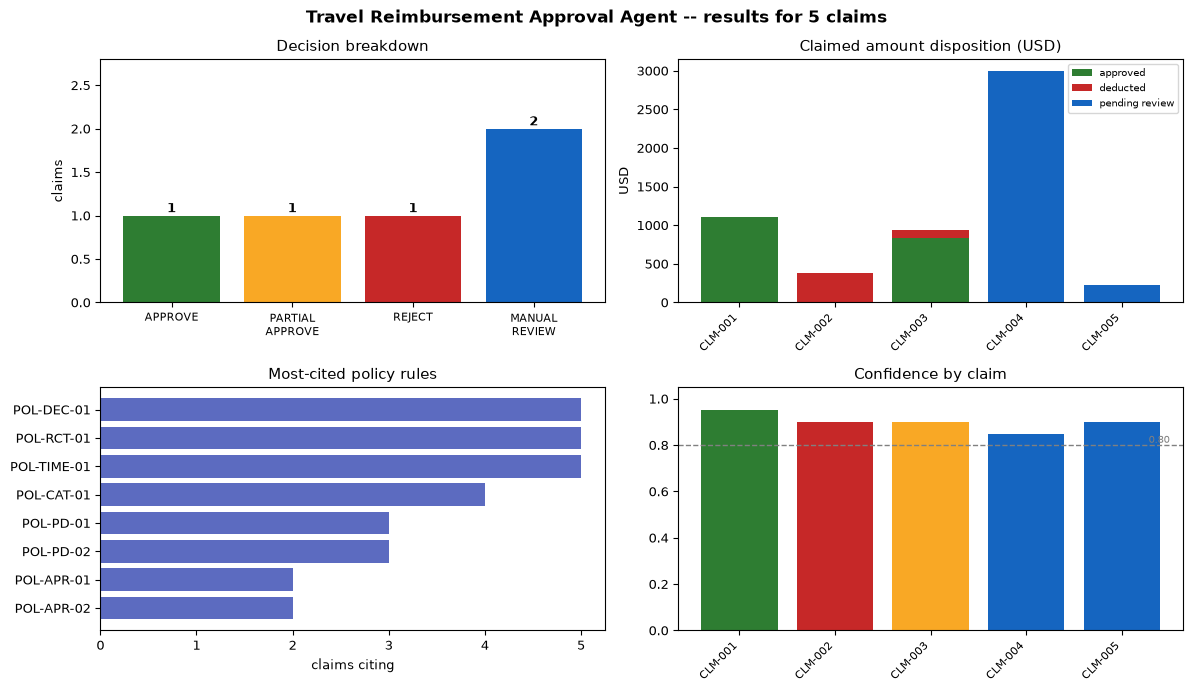

,value
claims,5
total claimed,"$5,650.00"
approved,"$1,950.00"
deducted,$480.00
pending review,"$3,220.00"
auto-decided,3 of 5
mean confidence,0.90


In [29]:
# --- Results dashboard ----------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams.update({"figure.autolayout": True, "font.size": 9})

df = pd.DataFrame(RESULTS)
claimed = {c["claim_id"]: sum(li["amount"] for li in c["line_items"]) for c in CLAIMS}
df["total_claimed"] = df["claim_id"].map(claimed)
# MANUAL_REVIEW asserts no amounts, so its money sits in a third bucket: awaiting a human.
df["pending_review"] = df.apply(
    lambda r: r["total_claimed"] if r["decision"] == "MANUAL_REVIEW" else 0.0, axis=1)

ORDER = ["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]
COLOR = {"APPROVE": "#2e7d32", "PARTIAL_APPROVE": "#f9a825",
         "REJECT": "#c62828", "MANUAL_REVIEW": "#1565c0"}

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
fig.suptitle("Travel Reimbursement Approval Agent -- results for %d claims" % len(df),
             fontsize=12, fontweight="bold")

# 1. decision breakdown
counts = df["decision"].value_counts().reindex(ORDER).fillna(0)
ax[0][0].bar(range(len(ORDER)), counts.values,
             color=[COLOR[d] for d in ORDER])
ax[0][0].set_xticks(range(len(ORDER)))
ax[0][0].set_xticklabels([d.replace("_", "\n") for d in ORDER], fontsize=8)
ax[0][0].set_title("Decision breakdown")
ax[0][0].set_ylabel("claims")
for i, v in enumerate(counts.values):
    if v:
        ax[0][0].text(i, v + 0.04, "%d" % v, ha="center", fontweight="bold")
ax[0][0].set_ylim(0, max(counts.values) * 1.25 + 0.3)

# 2. money disposition per claim
x = range(len(df))
ax[0][1].bar(x, df["approved_amount"], label="approved", color="#2e7d32")
ax[0][1].bar(x, df["deducted_amount"], bottom=df["approved_amount"],
             label="deducted", color="#c62828")
ax[0][1].bar(x, df["pending_review"],
             bottom=df["approved_amount"] + df["deducted_amount"],
             label="pending review", color="#1565c0")
ax[0][1].set_xticks(list(x))
ax[0][1].set_xticklabels(df["claim_id"], rotation=45, ha="right", fontsize=8)
ax[0][1].set_title("Claimed amount disposition (USD)")
ax[0][1].legend(fontsize=7)
ax[0][1].set_ylabel("USD")

# 3. most-cited policy rules
cited: Dict[str, int] = {}
for refs in df["policy_refs"]:
    for r in refs:
        cited[r] = cited.get(r, 0) + 1
top = sorted(cited.items(), key=lambda kv: (-kv[1], kv[0]))[:8]
ax[1][0].barh([t[0] for t in top][::-1], [t[1] for t in top][::-1], color="#5c6bc0")
ax[1][0].set_title("Most-cited policy rules")
ax[1][0].set_xlabel("claims citing")

# 4. confidence per claim
ax[1][1].bar(x, df["confidence"], color=[COLOR[d] for d in df["decision"]])
ax[1][1].axhline(0.8, ls="--", lw=1, color="grey")
ax[1][1].text(len(df) - 0.5, 0.81, "0.80", fontsize=7, color="grey", ha="right")
ax[1][1].set_xticks(list(x))
ax[1][1].set_xticklabels(df["claim_id"], rotation=45, ha="right", fontsize=8)
ax[1][1].set_ylim(0, 1.05)
ax[1][1].set_title("Confidence by claim")

plt.savefig("dashboard.png", dpi=130, bbox_inches="tight")
plt.show()

totals = pd.DataFrame([{
    "claims": len(df),
    "total claimed": "${:,.2f}".format(df["total_claimed"].sum()),
    "approved": "${:,.2f}".format(df["approved_amount"].sum()),
    "deducted": "${:,.2f}".format(df["deducted_amount"].sum()),
    "pending review": "${:,.2f}".format(df["pending_review"].sum()),
    "auto-decided": "%d of %d" % ((df["decision"] != "MANUAL_REVIEW").sum(), len(df)),
    "mean confidence": "%.2f" % df["confidence"].mean(),
}])
display(totals.T.rename(columns={0: "value"}))

## 12. User interface

A results console plus a live control panel: pick a claim, change an amount or pull a
receipt, re-run the agent, watch the decision move. The static table above it always renders,
so this cell is never blank when the notebook is viewed on GitHub (widget state does not
survive a static render). Screenshots are saved as `UI SS_1.png` and `UI SS_2.png`.

In [30]:
# --- Minimal UI: the means by which a user interacts with this notebook ---------------
# A reviewer picks a claim, optionally edits an amount or pulls a receipt, and re-runs the
# agent live. Guarded so the notebook still completes where ipywidgets is unavailable, and
# it always renders a static result table so this cell is never blank on GitHub.
import html as _html

from IPython.display import HTML, display


def esc(text: Any) -> str:
    """Escape for HTML and write money as 'USD 75.00' rather than '$75.00'.

    Jupyter runs MathJax over rendered output, and a pair of '$' in an explanation gets
    treated as inline maths -- "$220.00 exceeds the cap of $75.00" renders as italic
    gibberish. An HTML entity does not help, because MathJax reads the rendered text, not
    the source. Spelling the currency out is unambiguous and immune to it.
    """
    return _html.escape(str(text)).replace("$", "USD ").replace("USD  ", "USD ")


def usd(amount: float) -> str:
    return "USD {:,.2f}".format(amount)


def result_html(row: Dict[str, Any], diag: Optional[Dict[str, Any]] = None) -> str:
    colour = {"APPROVE": "#2e7d32", "PARTIAL_APPROVE": "#f9a825",
              "REJECT": "#c62828", "MANUAL_REVIEW": "#1565c0"}[row["decision"]]
    chips = "".join(
        "<span style='background:#eceff1;border-radius:3px;padding:1px 6px;"
        "margin:0 3px 3px 0;display:inline-block;font:11px monospace'>%s</span>" % esc(r)
        for r in row["policy_refs"])
    docs = ("<ul style='margin:4px 0 0 16px;padding:0'>%s</ul>"
            % "".join("<li>%s</li>" % esc(d) for d in row["missing_docs"])
            ) if row["missing_docs"] else "<i style='color:#78909c'>none</i>"
    return """
    <div class="tex2jax_ignore" style="font-family:-apple-system,Segoe UI,sans-serif;max-width:860px;
                border:1px solid #cfd8dc;border-radius:6px;overflow:hidden;margin:6px 0">
      <div style="background:%s;color:#fff;padding:9px 14px;font-weight:600">
        %s &nbsp;&rarr;&nbsp; %s
        <span style="float:right;font-weight:400">confidence %.2f</span>
      </div>
      <table style="width:100%%;border-collapse:collapse;font-size:13px">
        <tr><td style="padding:7px 14px;width:150px;color:#546e7a">approved</td>
            <td style="padding:7px 14px;font-weight:600">%s</td></tr>
        <tr style="background:#fafafa"><td style="padding:7px 14px;color:#546e7a">deducted</td>
            <td style="padding:7px 14px;font-weight:600">%s</td></tr>
        <tr><td style="padding:7px 14px;color:#546e7a;vertical-align:top">missing docs</td>
            <td style="padding:7px 14px">%s</td></tr>
        <tr style="background:#fafafa">
            <td style="padding:7px 14px;color:#546e7a;vertical-align:top">policy refs</td>
            <td style="padding:7px 14px">%s</td></tr>
        <tr><td style="padding:7px 14px;color:#546e7a;vertical-align:top">tools used</td>
            <td style="padding:7px 14px;font:11px monospace">%s</td></tr>
        <tr style="background:#fafafa">
            <td style="padding:7px 14px;color:#546e7a;vertical-align:top">explanation</td>
            <td style="padding:7px 14px;line-height:1.5">%s</td></tr>
      </table>
    </div>""" % (colour, esc(row["claim_id"]), esc(row["decision"].replace("_", " ")),
                 row["confidence"], usd(row["approved_amount"]),
                 usd(row["deducted_amount"]),
                 docs, chips, esc(", ".join(row["tools_used"])), esc(row["explanation"]))


try:
    import ipywidgets as W

    claim_pick = W.Dropdown(options=[c["claim_id"] for c in CLAIMS],
                            value="CLM-003", description="Claim:")
    line_pick = W.Dropdown(options=[], description="Line:")
    amount = W.BoundedFloatText(value=0.0, min=0.0, max=100000.0, step=10.0,
                                description="Amount $:")
    receipt = W.Checkbox(value=True, description="receipt attached")
    run_btn = W.Button(description="Re-run agent", button_style="primary",
                       icon="refresh")
    reset_btn = W.Button(description="Reset", icon="undo")
    out = W.Output()

    def _claim(cid: str) -> Dict[str, Any]:
        return next(c for c in CLAIMS if c["claim_id"] == cid)

    def _sync_lines(*_: Any) -> None:
        c = _claim(claim_pick.value)
        line_pick.options = [li["line_id"] for li in c["line_items"]]
        line_pick.value = c["line_items"][0]["line_id"]
        _sync_amount()

    def _sync_amount(*_: Any) -> None:
        c = _claim(claim_pick.value)
        li = next(l for l in c["line_items"] if l["line_id"] == line_pick.value)
        amount.value = float(li["amount"])
        receipt.value = bool(li["receipt_attached"])

    def _run(*_: Any) -> None:
        with out:
            out.clear_output()
            c = json.loads(json.dumps(_claim(claim_pick.value)))   # deep copy
            for li in c["line_items"]:
                if li["line_id"] == line_pick.value:
                    li["amount"] = float(amount.value)
                    li["receipt_attached"] = bool(receipt.value)
            edited = from_form(c["claim_id"] + "-edited", c["employee"], c["purpose"],
                              c["trip_start"], c["trip_end"], c["submitted_date"],
                              c["line_items"])
            # Compare against every OTHER claim. The edited claim is a revision of this
            # one, not a second submission of it -- without this the duplicate detector
            # correctly, but unhelpfully, flags the edit as a duplicate of its original.
            peers = [other for other in CLAIMS if other["claim_id"] != c["claim_id"]]
            res = decide(edited, AGENT, peers)
            CACHE.save()
            display(HTML(result_html(res["row"], res["diagnostics"])))
            print("audit steps: %d | tools: %s"
                  % (len(res["audit"]), ", ".join(res["row"]["tools_used"])))

    claim_pick.observe(_sync_lines, names="value")
    line_pick.observe(_sync_amount, names="value")
    run_btn.on_click(_run)
    reset_btn.on_click(lambda *_: (_sync_amount(), out.clear_output()))
    _sync_lines()

    display(W.VBox([
        W.HTML("<h4 style='font-family:sans-serif;margin-bottom:2px'>Try it: edit a claim "
               "and re-run the agent</h4>"
               "<div style='font:12px sans-serif;color:#546e7a'>Raise CLM-003's lodging to "
               "see PARTIAL_APPROVE deepen; untick a receipt to force MANUAL_REVIEW "
               "(POL-RCT-02).</div>"),
        W.HBox([claim_pick, line_pick]),
        W.HBox([amount, receipt]),
        W.HBox([run_btn, reset_btn]),
        out]))
except ImportError:
    print("ipywidgets not installed -- the static results below still render; see "
          "'UI SS_1.png' for the interactive panel.")

# Static render of all five results, always produced, so this cell is never blank when the
# notebook is viewed on GitHub (widget state does not survive a static render).
display(HTML("<div class='tex2jax_ignore'><h4 style='font-family:sans-serif'>"
             "All five claims</h4>"
             + "".join(result_html(r, DIAGS.get(r["claim_id"])) for r in RESULTS)
             + "</div>"))

approved,"USD 1,110.00"
deducted,USD 0.00
missing docs,none
policy refs,POL-APR-02POL-CAT-01POL-DEC-01POL-PD-01POL-PD-02POL-RCT-01POL-TIME-01
tools used,"check_claim_level, check_line_items, validate_output"
explanation,"Approved in full: every line item is eligible, documented and within per-diem. Approval tier: manager on a gross provisional reimbursable of USD 1110.00 (submitted 10 days after the expense date). [agent] Claim appears complete and compliant; all items eligible with receipts attached; submission within 10 days meets timeliness policy; manager approval tier appropriate for USD 1,110 total."
approved,USD 0.00
deducted,USD 380.00
missing docs,none
policy refs,POL-APR-01POL-CAT-02POL-DEC-01POL-RCT-01POL-TIME-01
tools used,"check_claim_level, check_line_items, validate_draft, validate_output"


## 13. Tests

Four things are checked: the five expected business outcomes; the output contract; the money
invariant; and the safety property that **the LLM can never increase a payout or reverse an
escalation**.

A scripted transport then drives each merge branch deterministically, so the authority rules
are tested rather than asserted: the model *may* escalate a clean `APPROVE`; it may *not*
de-escalate, raise a payout, raise its own confidence, cite a policy id that does not exist, or
turn its own inferred category into a final `REJECT`. Unparseable output and a dead transport
both degrade to the engine with every claim still decided correctly.

Appendix B leaves several paths unexercised: the latest claim is 13 days old, so
`POL-TIME-01` never fires; the five claimants are distinct, so the duplicate detector never
fires; and no claim mixes eligible with ineligible items, so the partially-ineligible path to
`PARTIAL_APPROVE` is never taken. Synthetic claims cover those here. They are deliberately
kept out of the final JSON array, which stays at exactly the five provided claims.

In [31]:
# --- Tests / evaluation ---------------------------------------------------------------
# Covers the five Appendix B claims plus synthetic cases for the paths the appendix leaves
# unexercised (POL-TIME-01, duplicate detection, partially-ineligible -> PARTIAL_APPROVE).
EXPECTED = {
    "CLM-001": ("APPROVE",         1110.00,   0.00),
    "CLM-002": ("REJECT",             0.00, 380.00),
    "CLM-003": ("PARTIAL_APPROVE",  840.00, 100.00),
    "CLM-004": ("MANUAL_REVIEW",      0.00,   0.00),
    "CLM-005": ("MANUAL_REVIEW",      0.00,   0.00),
}

passed, failed = 0, []


def check(name: str, cond: bool, detail: str = "") -> None:
    global passed
    if cond:
        passed += 1
    else:
        failed.append("%s %s" % (name, detail))


# 1. business correctness on the five provided claims
for row in RESULTS:
    exp = EXPECTED[row["claim_id"]]
    got = (row["decision"], row["approved_amount"], row["deducted_amount"])
    check("decision/amounts %s" % row["claim_id"], got == exp,
          "expected %s got %s" % (exp, got))

# 2. output contract -- exact field set and order, types, known policy ids
for row in RESULTS:
    check("field order %s" % row["claim_id"], tuple(row.keys()) == FIELD_ORDER,
          str(tuple(row.keys())))
    check("decision enum %s" % row["claim_id"], row["decision"] in DECISIONS)
    check("list types %s" % row["claim_id"],
          all(isinstance(row[k], list)
              for k in ("missing_docs", "policy_refs", "tools_used")))
    check("known policy refs %s" % row["claim_id"],
          all(r in VALID_POLICY_IDS for r in row["policy_refs"]))
    check("tools used %s" % row["claim_id"], len(row["tools_used"]) >= 2,
          str(row["tools_used"]))
    check("confidence range %s" % row["claim_id"], 0.0 <= row["confidence"] <= 1.0)

# 3. money invariant
for row in RESULTS:
    tc = money(sum(li["amount"] for c in CLAIMS if c["claim_id"] == row["claim_id"]
                   for li in c["line_items"]))
    if row["decision"] == "MANUAL_REVIEW":
        check("no amounts asserted %s" % row["claim_id"],
              money(row["approved_amount"]) == 0 and money(row["deducted_amount"]) == 0)
    else:
        check("approved+deducted==claimed %s" % row["claim_id"],
              money(row["approved_amount"]) + money(row["deducted_amount"]) == tc,
              "%s + %s != %s" % (row["approved_amount"], row["deducted_amount"], tc))

# 4. paths the appendix does not exercise
for claim in from_json(TEST_CLAIMS_JSON):
    base = engine_decide(claim, batch=CLAIMS)
    check("synthetic %s (%s)" % (claim["claim_id"], claim["_why"]),
          base["decision"] == claim["_expect"],
          "expected %s got %s" % (claim["_expect"], base["decision"]))

# 5. the validator actually rejects bad rows
bad = dict(RESULTS[0])
bad["policy_refs"] = ["POL-NOPE-99"]
try:
    validate_output(bad, 1110.0)
    check("validator rejects unknown policy ref", False, "accepted a bogus ref")
except ValidationError:
    check("validator rejects unknown policy ref", True)

bad2 = dict(RESULTS[0])
bad2["approved_amount"] = 99999.0
try:
    validate_output(bad2, 1110.0)
    check("validator rejects broken money invariant", False, "accepted bad arithmetic")
except ValidationError:
    check("validator rejects broken money invariant", True)

# 6. the LLM can never loosen the engine (the core safety property)
for row in RESULTS:
    b = BASELINES[row["claim_id"]]
    check("LLM never raises payout %s" % row["claim_id"],
          money(row["approved_amount"]) <= money(b["approved_amount"]),
          "%s > %s" % (row["approved_amount"], b["approved_amount"]))
    if b["decision"] == "MANUAL_REVIEW":
        check("escalation never reversed %s" % row["claim_id"],
              row["decision"] == "MANUAL_REVIEW")

# 7. the authority rules, driven by a scripted transport so each branch is deterministic
class ScriptedTransport:
    """Returns canned replies, so the merge rules can be tested without a live model."""
    available = True
    name = "scripted(test)"

    def __init__(self, replies: List[str]):
        self.replies, self.n = list(replies), 0

    def complete(self, prompt: str) -> str:
        reply = self.replies[min(self.n, len(self.replies) - 1)]
        self.n += 1
        return reply


def scripted(claim: Dict[str, Any], replies: List[str]) -> Dict[str, Any]:
    return decide(claim, Agent(ScriptedTransport(replies), cache=None, use_llm=True), CLAIMS)


_look = json.dumps({"thought": "gather facts", "action": "check_line_items", "args": {}})
ESC_CLAIMS = from_json(LLM_ESCALATION_CLAIMS_JSON)

# 7a. the model MAY escalate a clean APPROVE (this is its real authority)
_r = scripted(ESC_CLAIMS[0], [_look, json.dumps({"thought": "personal celebration", "final": {
    "escalate_to_manual_review": True,
    "escalation_reason": "Stated purpose is a personal celebration (POL-CAT-02).",
    "confidence_cap": 0.55}})])
check("model may escalate a clean APPROVE",
      _r["baseline"]["decision"] == "APPROVE"
      and _r["row"]["decision"] == "MANUAL_REVIEW"
      and _r["row"]["approved_amount"] == 0.0,
      "%s -> %s" % (_r["baseline"]["decision"], _r["row"]["decision"]))

# 7b. the model may NOT de-escalate, raise a payout, raise confidence, or invent a POL id
_r = scripted(CLAIMS[3], [_look, json.dumps({"thought": "looks fine", "final": {
    "escalate_to_manual_review": False,
    "confidence_cap": 0.99,
    "additional_policy_refs": ["POL-FAKE-99", "POL-AIR-01"],
    "notes": ["I think this is approvable."]}})])
check("de-escalation refused", _r["row"]["decision"] == "MANUAL_REVIEW", _r["row"]["decision"])
check("payout not raised", _r["row"]["approved_amount"] == 0.0)
check("confidence not raised",
      _r["row"]["confidence"] <= _r["baseline"]["confidence"])
check("hallucinated policy ref dropped", "POL-FAKE-99" not in _r["row"]["policy_refs"])

# 7c. a remap the model inferred may withhold money but may not FINALLY reject a claim
_r = scripted(ESC_CLAIMS[1], [_look, json.dumps({"thought": "bundled ineligibles", "final": {
    "escalate_to_manual_review": True,
    "escalation_reason": "Bundled spa and minibar charges (POL-CAT-02).",
    "category_corrections": {"L1": "spa"}}})])
check("model-inferred remap cannot finally reject",
      _r["row"]["decision"] == "MANUAL_REVIEW", _r["row"]["decision"])

# 7d. unparseable model output degrades to the engine baseline
_r = scripted(CLAIMS[0], ["I cannot help with that.", "Sorry, no JSON here.", "nope"])
check("garbage model output degrades to the engine",
      _r["row"]["decision"] == "APPROVE" and _r["row"]["approved_amount"] == 1110.00,
      "%s %s" % (_r["row"]["decision"], _r["row"]["approved_amount"]))


# 7e. a transport that always fails opens the circuit breaker and still decides every claim
class BrokenTransport:
    available = True
    name = "broken(test)"

    def complete(self, prompt: str) -> str:
        raise RuntimeError("transport unavailable")


_broken = Agent(BrokenTransport(), cache=None, use_llm=True)
_rows = [decide(c, _broken, CLAIMS)["row"] for c in CLAIMS[:3]]
check("circuit breaker opens after repeated transport failure", _broken.breaker_open)
check("every claim still decided with a dead transport",
      [r["decision"] for r in _rows] == ["APPROVE", "REJECT", "PARTIAL_APPROVE"],
      str([r["decision"] for r in _rows]))

print("=" * 70)
print("%d checks passed, %d failed" % (passed, len(failed)))
for f in failed:
    print("  FAIL:", f)
print("=" * 70)
assert not failed, "%d test(s) failed" % len(failed)
print("ALL TESTS PASSED")

61 checks passed, 0 failed
ALL TESTS PASSED


## Design Notes & Reasoning

### Assumptions

1. **Per-diem units come from the trip dates**, not from the line description:
   `nights = trip_end - trip_start`, `days = nights + 1`. Free text is parsed *only* to detect
   a conflict with the dates. The alternative, trusting the claimant's own "3 nights", lets
   a claim set its own cap, which is the wrong default for a control.
2. **The approval tier is computed on the gross provisional reimbursable** (every eligible
   item at its capped value, including items held for review). Discussed above; without this,
   `POL-APR-03` arguably does not fire on CLM-004.
3. **`confidence` is confidence in the recommended next action**, not in the claim's
   validity. A claim with three certain hard triggers is one we are *very* sure needs a human,
   so it scores high. The free model consistently conflated the two and tried to drive CLM-004
   to 0.30, so the reduction is floored at 0.50 and the distinction is spelled out in the
   prompt.
4. **`MANUAL_REVIEW` asserts no amounts**: `approved_amount` and `deducted_amount` are both
   `0.00`, with the provisional figures stated in `explanation`. `approved_amount` is a
   payment instruction, and a non-zero value on a row nobody approved is how a downstream
   consumer that filters on `approved_amount > 0` pays a claim by accident. The dashboard
   recovers the withheld money as a third "pending review" series by joining back to the
   claimed totals.
5. **The expense date for `POL-TIME-01` is `trip_start`**: the strictest reading. It makes no
   difference on these five claims.
6. An ineligible item's missing receipt is not chased: the item can never be paid.
7. `fare_class` is inferred from the description, since Appendix B encodes it in prose.

### Trade-offs

- **Deterministic engine as the floor, LLM as a tightener.** The central trade-off. It costs
  the ability to have the model find a *more generous* reading a human would accept, and buys
  a bound on the failure mode: the model can over-escalate, never over-pay. For money, that
  is the right direction to be wrong in, and it is why a free small model is usable here at
  all.
- **No native tool-calling.** Not a choice: OpenCode Zen returns `403 FreeTierError` for
  free-tier models called over HTTP, so the only route to a free model is the opencode CLI,
  which offers no `tools:[]` API. Hence the JSON protocol. A single `AnthropicTransport`
  routes through the same loop rather than a second native-tool-use code path, because two
  orchestration paths where only one can be tested is worse than one.
- **Two gates on escalation, added from observed failure.** The first full run escalated
  CLM-001, the cleanest claim in the set, because the model answered before calling any
  tool and then cited five invented policy ids. Rather than weaken the model's authority, the
  loop was fixed: a verdict formed before the mandatory checks have run is refused and
  reconsidered with the facts, and an escalation must cite a real rule or report a concrete
  gap. This is the clearest illustration of the whole design philosophy: the model keeps
  real authority, but every exercise of it has to be grounded in something checkable.
- **Response cache over temperature control.** The CLI exposes no seed, so reproducibility is
  bought with a committed prompt-hash cache. The cost is that a stale cache hides model
  regressions; `REFRESH_LLM_CACHE=1` is the documented escape hatch.
- **Token-overlap retrieval, not embeddings.** 13 records. A vector store would be a
  dependency and a loading step in exchange for nothing measurable.
- **Four tools exposed, seven checks underneath.** Small models degrade badly as the tool
  surface grows. Granularity is kept internally where it helps testing, not externally where
  it hurts reliability.
- **One decision per claim.** The schema permits exactly one `decision` and one amount pair,
  so a *split settlement* (pay the clean lines, hold only the ambiguous ones) cannot be
  represented faithfully. It is the better business answer for CLM-004 and it is what I would
  build next if the schema allowed it.

### Why these cases route to Manual Review

- **CLM-004**: three independent triggers: a business-class fare that policy says to review
  rather than deduct, because a pre-approval may exist (`POL-AIR-01`); a missing lodging
  receipt, which `POL-RCT-02` says to *ask* for rather than silently reject; and USD 2,800 gross,
  above the agent's authority (`POL-APR-03`). Plus a material contradiction in the claim.
- **CLM-005**: a missing receipt on a USD 220 item (`POL-RCT-02`), and underneath it a genuine
  policy gap: nothing in Appendix A addresses multi-attendee client hospitality. Forcing
  either USD 75 or USD 300 would be inventing policy.
- **Deliberately *not* Manual Review: CLM-002.** Spa and minibar are named verbatim in
  `POL-CAT-02` and nothing is reimbursable, which is exactly `POL-DEC-01`'s definition of
  `REJECT`. "Prefer Manual Review" is a tie-breaker for ambiguity, not a licence to escalate
  the one fully determinate claim in the set.

### Known gaps

- `POL-PD-03` (ground transport) is implemented but no sample claim exercises it.
- Duplicate detection runs against a two-row stub ledger standing in for a claims-database
  query, plus within-batch comparison. It matches on employee + trip start + exact total, so
  a near-duplicate with a different total slips through.
- Per-diem caps are applied per category across the whole trip, not per day. A claim that is
  within the trip total but wildly over on one day would pass. Per-day line items would fix
  it; Appendix B does not provide dated line items.
- No currency handling: everything is USD, as the appendix states.
- The free model is the weakest link: it returns prose instead of JSON perhaps one call in
  five, invents policy ids, and will answer before looking if allowed to. The parser, the
  corrective re-prompt, the facts gate, the grounding gate, the host backstop and the engine
  floor between them mean this degrades output *quality*, never correctness, but a stronger
  model would produce visibly better explanations and reviewer questions for the same code.
- The grounding gate is a keyword-and-citation check, not a semantic one. A well-worded but
  spurious escalation that cites a real rule would still be accepted. It bounds obvious
  nonsense, not sophisticated nonsense.

### What I would improve next

1. **Split settlement**: approve the clean lines and hold only the ambiguous ones, which
   needs a richer output schema than this assignment specifies.
2. **Per-day line items** so per-diem caps apply per day as the policy actually intends.
3. **An evaluation set with labels**, so prompt changes can be scored instead of eyeballed:
   roughly 30 claims covering each rule and each decision, run as a scored suite in CI.
4. **Receipt OCR** to check that the attached receipt matches the claimed amount and vendor,
   which is the obvious next fraud vector once receipts are merely *present*.
5. **Confidence calibration**: the current scores are a documented rubric, not calibrated
   probabilities. With a labelled set they could be fitted to observed reviewer agreement.
6. **MCP tool integration** so the same tools serve other agents, now that they are already
   pure functions with JSON in and JSON out.

## Assumptions & Limitations

**Assumptions**: per-diem units derive from trip dates, not claim text; approval tiers use
the gross provisional reimbursable; `MANUAL_REVIEW` asserts no amounts; `POL-TIME-01` measures
from `trip_start`; airfare class is inferred from the description; all amounts are USD.

**Simplifications**: token-overlap retrieval rather than embeddings; a two-row stub ledger
in place of a claims database; four LLM-visible tools over seven internal checks; per-category
rather than per-day per-diem application; one decision per claim.

**Known gaps**: `POL-PD-03` untested by the sample data; duplicate detection matches only on
an exact total; no OCR or receipt-content verification; confidence scores are a rubric, not
calibrated probabilities; the free model sometimes returns prose instead of JSON.

**Guardrails that make the above safe**: the deterministic engine owns all arithmetic and
every hard trigger; the LLM can only tighten a decision, never loosen it; every row is
validated against a 9-field contract, a decision enum, a closed set of policy ids and a money
invariant; hallucinated policy citations are dropped; a timeout plus circuit breaker degrades
to the engine; and with no LLM at all the notebook still runs and still passes every test.

**Scope**: a timeboxed prototype, not a production system. No auth, no persistence, no
concurrency, no PII handling, and no real employee or company data.

## Final output

One object per provided claim, with exactly the nine contracted fields: `claim_id`,
`decision`, `approved_amount`, `deducted_amount`, `missing_docs`, `policy_refs`, `confidence`,
`explanation`, `tools_used`.

In [32]:
# --- FINAL OUTPUT: one object per provided claim, exactly the nine contracted fields ---
for _row in RESULTS:
    assert tuple(_row.keys()) == FIELD_ORDER, "field contract violated"

print(json.dumps(RESULTS, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-APR-02",
      "POL-CAT-01",
      "POL-DEC-01",
      "POL-PD-01",
      "POL-PD-02",
      "POL-RCT-01",
      "POL-TIME-01"
    ],
    "confidence": 0.95,
    "explanation": "Approved in full: every line item is eligible, documented and within per-diem. Approval tier: manager on a gross provisional reimbursable of $1110.00 (submitted 10 days after the expense date). [agent] Claim appears complete and compliant; all items eligible with receipts attached; submission within 10 days meets timeliness policy; manager approval tier appropriate for $1,110 total.",
    "tools_used": [
      "check_claim_level",
      "check_line_items",
      "validate_output"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_